# 08 — ML Final Evaluation

This notebook loads only the frozen Random Forest and XGBoost configurations selected by the completed `shared_family_balanced_v1` tuning protocol. Four final models are fitted on observed Train rows and evaluated on artificially masked Test rows across all five scenarios.

The Test split is not used for model selection. Predictions are evaluated as generated. Negative predictions, if any, are retained and counted rather than clipped after seeing Test results.

Outputs and final-model checkpoints are stored in protocol-specific folders so that earlier random30-only results cannot be resumed or mistaken for the shared-tuning evaluation.


In [1]:
# Core utilities
from importlib.metadata import PackageNotFoundError, version
from pathlib import Path
from packaging.version import Version
from time import perf_counter
import gc
import hashlib
import json
import os
import platform
import random
import re
import sys

# Data handling
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Machine-learning utilities
import sklearn
from joblib import dump, load
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    median_absolute_error,
    r2_score,
)
from threadpoolctl import threadpool_limits

try:
    import xgboost
    from xgboost import XGBRegressor
    XGBOOST_AVAILABLE = True
except ImportError:
    xgboost = None
    XGBRegressor = None
    XGBOOST_AVAILABLE = False

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")


## Step 1 : Configuration

The notebook accepts only full shared family-balanced tuning artifacts created under `shared_family_balanced_v1`. Final model fitting uses one model-level worker and is timed once. Inference is warmed up, repeated five times, and summarised by the median. Verified protocol-specific final-model checkpoints may be reused after an interrupted run.


In [2]:
SEED = 42

RUNTIME_N_JOBS = 1
FINAL_FIT_REPEATS = 1
INFERENCE_REPEATS = 5
RESUME_FINAL_MODELS = True

EXPECTED_TUNING_CANDIDATES = 30
EXPECTED_XGBOOST_VERSION = "3.2.0"

TUNING_PROTOCOL = "shared_family_balanced"
TUNING_PROTOCOL_VERSION = "shared_family_balanced_v1"
TUNING_METRIC = "FamilyBalancedValidationMAE"
REFERENCE_SCENARIO = "random30_point"
ARTIFACT_TAG = "shared_family_balanced"

SELECTION_SORT_COLUMNS = [
    "FamilyBalancedValidationMAE",
    "FamilyBalancedValidationRMSE",
    "FitSeconds",
    "CandidateNumber",
]

SCENARIO_FAMILIES = {
    "random_point": [
        "random10_point",
        "random30_point",
        "random50_point",
    ],
    "block_gap": [
        "block24_10percent",
        "block72_10percent",
    ],
}

FAMILY_WEIGHTS = {
    "random_point": 0.5,
    "block_gap": 0.5,
}

EVALUATION_SPLIT = "Test"

ML_PIPELINE_VERSION = "ml_features_v2_2026-07-19"

random.seed(SEED)
np.random.seed(SEED)

TIME_COL = "Datetime"
STATION_COL = "Station"
SPLIT_COL = "Split"
SCENARIO_COL = "MaskingScenario"
TARGET_COL = "PM25_original"
MODEL_INPUT_COL = "PM25_model_input"
TEMPERATURE_COL = "Temperature"
FLAG_COLUMN = "is_artificial_masked"

SCENARIOS = [
    "random10_point",
    "random30_point",
    "random50_point",
    "block24_10percent",
    "block72_10percent",
]

FEATURE_SETS = [
    "temporal_only",
    "spatio_temporal",
]

MODEL_NAMES = [
    "RandomForest",
    "XGBoost",
]

TRAIN_LABEL = "Train"
VALIDATION_LABEL = "Validation"
TEST_LABEL = "Test"

SUPPORTED_INPUT_SUFFIXES = {
    ".csv",
    ".parquet",
    ".pkl",
    ".pickle",
    ".feather",
}

NOTEBOOK_DIR = Path.cwd().resolve()


def find_codes_dir(start_path):
    """Locate the main Codes folder."""

    for path in [start_path, *start_path.parents]:
        if path.name.lower() == "codes":
            return path

    raise FileNotFoundError(
        f"Could not locate the Codes folder from: {start_path}"
    )


def find_table(folder, stem):
    """Find one supported table by filename stem."""

    matches = [
        path
        for path in folder.iterdir()
        if path.is_file()
        and path.stem.lower() == stem.lower()
        and path.suffix.lower() in SUPPORTED_INPUT_SUFFIXES
    ]

    if not matches:
        raise FileNotFoundError(
            f"Required file not found: {folder / stem}"
        )

    if len(matches) > 1:
        raise ValueError(
            f"Multiple files found for '{stem}': {matches}"
        )

    return matches[0]


if not XGBOOST_AVAILABLE:
    raise ImportError(
        "Notebook 07 requires xgboost. Install it, restart the "
        "kernel, and run the notebook again."
    )

if Version(xgboost.__version__) != Version(EXPECTED_XGBOOST_VERSION):
    raise RuntimeError(
        "The final evaluation must use the XGBoost version audited "
        f"during shared tuning. Expected {EXPECTED_XGBOOST_VERSION}; "
        f"found {xgboost.__version__}."
    )

if FINAL_FIT_REPEATS != 1:
    raise ValueError(
        "The pre-specified protocol requires one final fit."
    )

if INFERENCE_REPEATS != 5:
    raise ValueError(
        "The pre-specified protocol requires five inference repetitions."
    )

if not np.isclose(
    sum(FAMILY_WEIGHTS.values()),
    1.0,
):
    raise ValueError(
        "Family weights must sum to one."
    )

scenario_family_members = [
    scenario
    for family_scenarios in SCENARIO_FAMILIES.values()
    for scenario in family_scenarios
]

if (
    sorted(scenario_family_members) != sorted(SCENARIOS)
    or len(scenario_family_members) != len(set(scenario_family_members))
):
    raise ValueError(
        "Each tuning scenario must appear exactly once in the "
        "scenario-family definition."
    )

CODES_DIR = find_codes_dir(NOTEBOOK_DIR)

DATA_DIR = CODES_DIR / "data" / "modelling"
PROCESSED_DIR = CODES_DIR / "data" / "processed"
RESULTS_DIR = CODES_DIR / "results"
MODELS_DIR = CODES_DIR / "models"

OUTPUT_DIR = RESULTS_DIR / "machine_learning"

# Protocol-specific outputs prevent old random30-only results from being reused.
FINAL_OUTPUT_DIR = (
    OUTPUT_DIR
    / "final_evaluation"
    / TUNING_PROTOCOL_VERSION
)

MODEL_DIR = MODELS_DIR / "machine_learning"
FINAL_MODEL_DIR = (
    MODEL_DIR
    / "final_models"
    / TUNING_PROTOCOL_VERSION
)
FINAL_MODEL_MANIFEST_DIR = (
    FINAL_MODEL_DIR / "manifests"
)

PREDICTION_DIR = (
    FINAL_OUTPUT_DIR / "predictions_by_scenario"
)
FIGURE_DIR = (
    FINAL_OUTPUT_DIR / "figures"
)

for required_dir in [
    DATA_DIR,
    PROCESSED_DIR,
    RESULTS_DIR,
    MODELS_DIR,
]:
    if not required_dir.exists():
        raise FileNotFoundError(
            f"Required project folder not found: {required_dir}"
        )

for output_dir in [
    OUTPUT_DIR,
    FINAL_OUTPUT_DIR,
    MODEL_DIR,
    FINAL_MODEL_DIR,
    FINAL_MODEL_MANIFEST_DIR,
    PREDICTION_DIR,
    FIGURE_DIR,
]:
    output_dir.mkdir(
        parents=True,
        exist_ok=True,
    )

BASE_DATA_PATH = find_table(
    DATA_DIR,
    "base_modelling_dataset_before_masking",
)

SCENARIO_PATHS = {
    scenario: find_table(
        DATA_DIR,
        f"modelling_dataset_{scenario}_masked",
    )
    for scenario in SCENARIOS
}

STATION_METADATA_PATH = find_table(
    PROCESSED_DIR,
    "selected_station_metadata",
)
NEAREST_NEIGHBOURS_PATH = find_table(
    PROCESSED_DIR,
    "top3_nearest_neighbours",
)
IDW_WEIGHTS_PATH = find_table(
    PROCESSED_DIR,
    "top3_idw_weights",
)

ARTIFACT_SUFFIX = f"_{ARTIFACT_TAG}"

TUNING_ARTIFACT_PATHS = {
    "RandomForest": {
        feature_set: (
            MODEL_DIR
            / (
                "random_forest_best_parameters_"
                f"{feature_set}"
                f"{ARTIFACT_SUFFIX}.json"
            )
        )
        for feature_set in FEATURE_SETS
    },
    "XGBoost": {
        feature_set: (
            MODEL_DIR
            / (
                "xgboost_best_parameters_"
                f"{feature_set}"
                f"{ARTIFACT_SUFFIX}.json"
            )
        )
        for feature_set in FEATURE_SETS
    },
}

TUNING_MANIFEST_PATH = (
    OUTPUT_DIR
    / f"ml_tuning_manifest{ARTIFACT_SUFFIX}.json"
)

TUNING_RUNTIME_SUMMARY_PATH = (
    OUTPUT_DIR
    / f"ml_tuning_runtime_summary{ARTIFACT_SUFFIX}.csv"
)

print(f"Codes directory: {CODES_DIR}")
print(f"Shared tuning protocol: {TUNING_PROTOCOL_VERSION}")
print(f"Selection metric: {TUNING_METRIC}")
print(f"Final results: {FINAL_OUTPUT_DIR}")
print(f"Final models: {FINAL_MODEL_DIR}")
print(f"XGBoost version: {xgboost.__version__}")
print(f"Final model workers: {RUNTIME_N_JOBS}")
print(f"Inference repetitions: {INFERENCE_REPEATS}")


Codes directory: C:\Users\Msi\Desktop\DISSERTATION\Codes
Shared tuning protocol: shared_family_balanced_v1
Selection metric: FamilyBalancedValidationMAE
Final results: C:\Users\Msi\Desktop\DISSERTATION\Codes\results\machine_learning\final_evaluation\shared_family_balanced_v1
Final models: C:\Users\Msi\Desktop\DISSERTATION\Codes\models\machine_learning\final_models\shared_family_balanced_v1
XGBoost version: 3.2.0
Final model workers: 1
Inference repetitions: 5


## Step 2 : Input and Shared-Tuning Artifact Validation

All masked datasets are checked against the common base panel. The current five scenario fingerprints are combined exactly as they were during shared tuning. Only completed full artifacts with the expected protocol, family weights, selection metric, tie-break order, package versions and data fingerprints are accepted. Pilot and earlier random30-only artifacts are deliberately rejected.


In [3]:
def package_version(package_name):
    """Return an installed package version when available."""

    try:
        return version(package_name)
    except PackageNotFoundError:
        return "Not installed"


def read_table(path):
    """Read one supported table."""

    suffix = path.suffix.lower()

    if suffix == ".csv":
        df = pd.read_csv(path)
    elif suffix == ".parquet":
        df = pd.read_parquet(path)
    elif suffix in {".pkl", ".pickle"}:
        df = pd.read_pickle(path)
    elif suffix == ".feather":
        df = pd.read_feather(path)
    else:
        raise ValueError(
            f"Unsupported input format: {path}"
        )

    if TIME_COL in df.columns:
        df[TIME_COL] = pd.to_datetime(
            df[TIME_COL]
        )

    return df


def read_json(path):
    """Read one JSON file."""

    with open(
        path,
        "r",
        encoding="utf-8",
    ) as file:
        return json.load(file)


def to_json_safe(value):
    """Convert values to JSON-compatible objects."""

    if isinstance(value, dict):
        return {
            str(key): to_json_safe(item)
            for key, item in value.items()
        }

    if isinstance(value, (list, tuple)):
        return [
            to_json_safe(item)
            for item in value
        ]

    if isinstance(value, np.generic):
        return value.item()

    if isinstance(value, Path):
        return str(value)

    return value


def canonical_json(value):
    """Return deterministic JSON text."""

    return json.dumps(
        to_json_safe(value),
        sort_keys=True,
        separators=(",", ":"),
        allow_nan=False,
    )


def stable_hash(value):
    """Create a reproducible SHA-256 hash."""

    return hashlib.sha256(
        canonical_json(value).encode("utf-8")
    ).hexdigest()


def atomic_write_dataframe(df, path):
    """Write a CSV through an atomic replacement."""

    path = Path(path)
    temporary_path = path.with_suffix(
        path.suffix + ".tmp"
    )

    df.to_csv(
        temporary_path,
        index=False,
    )

    os.replace(
        temporary_path,
        path,
    )


def atomic_write_json(value, path):
    """Write JSON through an atomic replacement."""

    path = Path(path)
    temporary_path = path.with_suffix(
        path.suffix + ".tmp"
    )

    with open(
        temporary_path,
        "w",
        encoding="utf-8",
    ) as file:
        json.dump(
            to_json_safe(value),
            file,
            indent=4,
            sort_keys=True,
        )

    os.replace(
        temporary_path,
        path,
    )


def atomic_joblib_dump(value, path):
    """Write a joblib artifact through an atomic replacement."""

    path = Path(path)
    temporary_path = path.with_suffix(
        path.suffix + ".tmp"
    )

    dump(
        value,
        temporary_path,
    )

    os.replace(
        temporary_path,
        path,
    )


def to_boolean(series):
    """Convert a stored flag column to Boolean values."""

    if pd.api.types.is_bool_dtype(
        series
    ):
        return series.fillna(False)

    converted = (
        series.astype(str)
        .str.strip()
        .str.lower()
        .map(
            {
                "true": True,
                "false": False,
                "1": True,
                "0": False,
            }
        )
    )

    if converted.isna().any():
        raise ValueError(
            f"Invalid Boolean values in column: {series.name}"
        )

    return converted


def validate_input_labels(
    df,
    expected_scenario=None,
):
    """Check required columns and experiment labels."""

    required_columns = {
        TIME_COL,
        STATION_COL,
        SPLIT_COL,
        TARGET_COL,
        MODEL_INPUT_COL,
        TEMPERATURE_COL,
        FLAG_COLUMN,
    }

    missing_columns = (
        required_columns
        - set(df.columns)
    )

    if missing_columns:
        raise ValueError(
            f"Missing required columns: {sorted(missing_columns)}"
        )

    observed_splits = set(
        df[SPLIT_COL]
        .dropna()
        .astype(str)
        .unique()
    )

    expected_splits = {
        TRAIN_LABEL,
        VALIDATION_LABEL,
        TEST_LABEL,
    }

    if observed_splits != expected_splits:
        raise ValueError(
            "Split labels do not match the expected "
            f"labels: {sorted(observed_splits)}"
        )

    if expected_scenario is not None:
        if SCENARIO_COL not in df.columns:
            raise ValueError(
                f"Missing scenario column: {SCENARIO_COL}"
            )

        observed_scenarios = set(
            df[SCENARIO_COL]
            .dropna()
            .astype(str)
            .unique()
        )

        if observed_scenarios != {
            expected_scenario
        }:
            raise ValueError(
                f"Scenario mismatch for {expected_scenario}: "
                f"{sorted(observed_scenarios)}"
            )


def load_scenario(scenario):
    """Load and validate one masking scenario."""

    if scenario not in SCENARIO_PATHS:
        raise KeyError(
            f"Unknown scenario: {scenario}"
        )

    df = read_table(
        SCENARIO_PATHS[scenario]
    )

    validate_input_labels(
        df,
        expected_scenario=scenario,
    )

    return df


def dataframe_fingerprint(df):
    """Fingerprint the exact modelling values used by tuning."""

    fingerprint_columns = [
        STATION_COL,
        TIME_COL,
        SPLIT_COL,
        SCENARIO_COL,
        TARGET_COL,
        MODEL_INPUT_COL,
        TEMPERATURE_COL,
        FLAG_COLUMN,
    ]

    ordered = (
        df[fingerprint_columns]
        .sort_values(
            [STATION_COL, TIME_COL]
        )
        .reset_index(drop=True)
        .copy()
    )

    ordered[TIME_COL] = pd.to_datetime(
        ordered[TIME_COL]
    )

    row_hashes = pd.util.hash_pandas_object(
        ordered,
        index=False,
    ).to_numpy(dtype="uint64")

    return hashlib.sha256(
        row_hashes.tobytes()
    ).hexdigest()


In [4]:
base_df = read_table(
    BASE_DATA_PATH
)

validate_input_labels(
    base_df
)

KEY_COLUMNS = [
    STATION_COL,
    TIME_COL,
]

if SCENARIO_COL in base_df.columns:
    base_df = base_df.drop(
        columns=[SCENARIO_COL]
    )

if base_df.duplicated(
    KEY_COLUMNS
).any():
    raise ValueError(
        "Duplicate Station-Datetime rows in base data."
    )

base_artificial = to_boolean(
    base_df[FLAG_COLUMN]
)

if base_artificial.any():
    raise ValueError(
        "Artificial masks should not exist in base data."
    )

base_sorted = (
    base_df
    .sort_values(KEY_COLUMNS)
    .reset_index(drop=True)
)

base_split_counts = (
    base_sorted[SPLIT_COL]
    .value_counts()
    .sort_index()
)

base_station_counts = (
    base_sorted[STATION_COL]
    .value_counts()
    .sort_index()
)

scenario_audit_records = []
mask_audit_records = []
CURRENT_SCENARIO_DATA_FINGERPRINTS = {}

for scenario in SCENARIOS:
    df = load_scenario(
        scenario
    )

    CURRENT_SCENARIO_DATA_FINGERPRINTS[
        scenario
    ] = dataframe_fingerprint(
        df
    )

    duplicate_count = int(
        df.duplicated(
            KEY_COLUMNS
        ).sum()
    )

    if duplicate_count:
        raise ValueError(
            f"{scenario}: duplicate rows found."
        )

    df_sorted = (
        df
        .sort_values(KEY_COLUMNS)
        .reset_index(drop=True)
    )

    if len(df_sorted) != len(
        base_sorted
    ):
        raise ValueError(
            f"{scenario}: row count differs from base."
        )

    if not df_sorted[
        KEY_COLUMNS
    ].equals(
        base_sorted[
            KEY_COLUMNS
        ]
    ):
        raise ValueError(
            f"{scenario}: keys differ from base."
        )

    if not (
        df_sorted[SPLIT_COL]
        .value_counts()
        .sort_index()
        .equals(base_split_counts)
    ):
        raise ValueError(
            f"{scenario}: split counts differ from base."
        )

    if not (
        df_sorted[STATION_COL]
        .value_counts()
        .sort_index()
        .equals(base_station_counts)
    ):
        raise ValueError(
            f"{scenario}: station counts differ from base."
        )

    base_original = pd.to_numeric(
        base_sorted[TARGET_COL],
        errors="coerce",
    ).to_numpy()

    scenario_original = pd.to_numeric(
        df_sorted[TARGET_COL],
        errors="coerce",
    ).to_numpy()

    if not np.allclose(
        base_original,
        scenario_original,
        equal_nan=True,
    ):
        raise ValueError(
            f"{scenario}: PM25_original differs from base."
        )

    artificial_mask = to_boolean(
        df_sorted[FLAG_COLUMN]
    )

    original = pd.to_numeric(
        df_sorted[TARGET_COL],
        errors="coerce",
    )

    model_input = pd.to_numeric(
        df_sorted[MODEL_INPUT_COL],
        errors="coerce",
    )

    if original[
        artificial_mask
    ].isna().any():
        raise ValueError(
            f"{scenario}: masked rows lack ground truth."
        )

    if model_input[
        artificial_mask
    ].notna().any():
        raise ValueError(
            f"{scenario}: masked targets remain visible."
        )

    real_missing = original.isna()

    if model_input[
        real_missing
    ].notna().any():
        raise ValueError(
            f"{scenario}: real missing values became visible."
        )

    visible_observed = (
        ~artificial_mask
        & original.notna()
    )

    if not np.allclose(
        model_input[
            visible_observed
        ],
        original[
            visible_observed
        ],
        equal_nan=True,
    ):
        raise ValueError(
            f"{scenario}: visible observations changed."
        )

    train_artificial = int(
        artificial_mask[
            df_sorted[SPLIT_COL].eq(
                TRAIN_LABEL
            )
        ].sum()
    )

    if train_artificial != 0:
        raise ValueError(
            f"{scenario}: Train contains artificial masks."
        )

    eligible_count = int(
        original.notna().sum()
    )

    artificial_count = int(
        artificial_mask.sum()
    )

    scenario_audit_records.append(
        {
            "Scenario": scenario,
            "Rows": len(df_sorted),
            "Stations": df_sorted[
                STATION_COL
            ].nunique(),
            "Duplicates": duplicate_count,
            "EligibleObserved": eligible_count,
            "ArtificialMasks": artificial_count,
            "OverallPanelMaskRate": (
                artificial_count
                / eligible_count
            ),
            "RealMissing": int(
                real_missing.sum()
            ),
        }
    )

    audit_table = df_sorted[
        [SPLIT_COL, STATION_COL]
    ].copy()

    audit_table[
        "EligibleObserved"
    ] = original.notna().astype(int)

    audit_table[
        "ArtificialMasks"
    ] = artificial_mask.astype(int)

    audit_table = (
        audit_table
        .groupby(
            [SPLIT_COL, STATION_COL],
            as_index=False,
        )
        .agg(
            Rows=(STATION_COL, "size"),
            EligibleObserved=(
                "EligibleObserved",
                "sum",
            ),
            ArtificialMasks=(
                "ArtificialMasks",
                "sum",
            ),
        )
    )

    audit_table[
        "MaskRate"
    ] = (
        audit_table[
            "ArtificialMasks"
        ]
        / audit_table[
            "EligibleObserved"
        ]
    )

    audit_table.insert(
        0,
        "Scenario",
        scenario,
    )

    mask_audit_records.append(
        audit_table
    )

    del df, df_sorted, audit_table


scenario_audit_summary = pd.DataFrame(
    scenario_audit_records
)

mask_audit_by_split_station = pd.concat(
    mask_audit_records,
    ignore_index=True,
)

atomic_write_dataframe(
    scenario_audit_summary,
    FINAL_OUTPUT_DIR
    / "scenario_input_audit.csv",
)

atomic_write_dataframe(
    mask_audit_by_split_station,
    FINAL_OUTPUT_DIR
    / "mask_audit_by_split_station.csv",
)

CURRENT_TUNING_DATA_FINGERPRINT = stable_hash(
    {
        "ProtocolVersion": (
            TUNING_PROTOCOL_VERSION
        ),
        "ScenarioFingerprints": (
            CURRENT_SCENARIO_DATA_FINGERPRINTS
        ),
    }
)

display(
    scenario_audit_summary
)

print(
    "Shared tuning-data fingerprint:",
    CURRENT_TUNING_DATA_FINGERPRINT[
        :16
    ],
)

print("Scenario fingerprints:")

for scenario, fingerprint in (
    CURRENT_SCENARIO_DATA_FINGERPRINTS.items()
):
    print(
        f"  {scenario}: {fingerprint[:16]}"
    )

print(
    "All five masking scenarios passed the input audit."
)


,Scenario,Rows,Stations,Duplicates,EligibleObserved,ArtificialMasks,OverallPanelMaskRate,RealMissing
0,random10_point,219120,5,0,214013,8650,0.0404,5107
1,random30_point,219120,5,0,214013,25951,0.1213,5107
2,random50_point,219120,5,0,214013,43250,0.2021,5107
3,block24_10percent,219120,5,0,214013,8784,0.0410,5107
4,block72_10percent,219120,5,0,214013,9144,0.0427,5107


Shared tuning-data fingerprint: 5828033a47e47911
Scenario fingerprints:
  random10_point: 249f865a49f951d4
  random30_point: ac3f585c96f61adb
  random50_point: ba807c03d75a906f
  block24_10percent: ddd99c0ebe9015ef
  block72_10percent: 290e1ef307c9a803
All five masking scenarios passed the input audit.


In [5]:
if not TUNING_MANIFEST_PATH.exists():
    raise FileNotFoundError(
        "The completed shared-tuning manifest is missing: "
        f"{TUNING_MANIFEST_PATH}"
    )

if not TUNING_RUNTIME_SUMMARY_PATH.exists():
    raise FileNotFoundError(
        "The shared-tuning runtime summary is missing: "
        f"{TUNING_RUNTIME_SUMMARY_PATH}"
    )

tuning_manifest = read_json(
    TUNING_MANIFEST_PATH
)

expected_manifest_values = {
    "Status": "complete",
    "TuningProfile": "full",
    "TuningCandidateCount": (
        EXPECTED_TUNING_CANDIDATES
    ),
    "TuningProtocol": (
        TUNING_PROTOCOL
    ),
    "TuningProtocolVersion": (
        TUNING_PROTOCOL_VERSION
    ),
    "SelectionMetric": (
        TUNING_METRIC
    ),
    "SelectionSortColumns": (
        SELECTION_SORT_COLUMNS
    ),
    "TuningScenarios": (
        SCENARIOS
    ),
    "ScenarioFamilies": (
        SCENARIO_FAMILIES
    ),
    "PipelineVersion": (
        ML_PIPELINE_VERSION
    ),
    "InputDataFingerprint": (
        CURRENT_TUNING_DATA_FINGERPRINT
    ),
    "ScenarioDataFingerprints": (
        CURRENT_SCENARIO_DATA_FINGERPRINTS
    ),
}

for field_name, expected_value in (
    expected_manifest_values.items()
):
    if tuning_manifest.get(
        field_name
    ) != expected_value:
        raise ValueError(
            "Shared-tuning manifest mismatch for "
            f"{field_name}: {TUNING_MANIFEST_PATH}"
        )

manifest_family_weights = (
    tuning_manifest.get(
        "FamilyWeights",
        {},
    )
)

if set(
    manifest_family_weights
) != set(
    FAMILY_WEIGHTS
):
    raise ValueError(
        "Shared-tuning manifest family-weight keys differ."
    )

for family_name, expected_weight in (
    FAMILY_WEIGHTS.items()
):
    if not np.isclose(
        float(
            manifest_family_weights[
                family_name
            ]
        ),
        expected_weight,
    ):
        raise ValueError(
            "Shared-tuning manifest family weight differs "
            f"for {family_name}."
        )

if tuning_manifest.get(
    "NestedRandomConditions"
) is not True:
    raise ValueError(
        "The shared-tuning manifest does not record nested "
        "random conditions."
    )

if Version(
    str(
        tuning_manifest.get(
            "ObservedXGBoostVersion"
        )
    )
) != Version(
    EXPECTED_XGBOOST_VERSION
):
    raise ValueError(
        "The XGBoost version in the tuning manifest differs "
        "from the audited version."
    )

TUNING_ARTIFACTS = {}
tuning_selection_records = []

for model_name in MODEL_NAMES:
    TUNING_ARTIFACTS[
        model_name
    ] = {}

    for feature_set_name in FEATURE_SETS:
        artifact_path = (
            TUNING_ARTIFACT_PATHS[
                model_name
            ][feature_set_name]
        )

        if not artifact_path.exists():
            raise FileNotFoundError(
                "Required shared full-tuning artifact not found: "
                f"{artifact_path}"
            )

        artifact = read_json(
            artifact_path
        )

        expected_artifact_values = {
            "Model": model_name,
            "FeatureSet": (
                feature_set_name
            ),
            "TuningProfile": "full",
            "TuningCandidateCount": (
                EXPECTED_TUNING_CANDIDATES
            ),
            "TuningProtocol": (
                TUNING_PROTOCOL
            ),
            "TuningProtocolVersion": (
                TUNING_PROTOCOL_VERSION
            ),
            "SelectionMetric": (
                TUNING_METRIC
            ),
            "SelectionSortColumns": (
                SELECTION_SORT_COLUMNS
            ),
            "TuningScenarios": (
                SCENARIOS
            ),
            "ScenarioFamilies": (
                SCENARIO_FAMILIES
            ),
            "PipelineVersion": (
                ML_PIPELINE_VERSION
            ),
            "InputDataFingerprint": (
                CURRENT_TUNING_DATA_FINGERPRINT
            ),
            "ScenarioDataFingerprints": (
                CURRENT_SCENARIO_DATA_FINGERPRINTS
            ),
            "ScikitLearnVersion": (
                sklearn.__version__
            ),
            "XGBoostVersion": (
                package_version(
                    "xgboost"
                )
            ),
        }

        for field_name, expected_value in (
            expected_artifact_values.items()
        ):
            if artifact.get(
                field_name
            ) != expected_value:
                raise ValueError(
                    "Shared tuning-artifact mismatch for "
                    f"{field_name}: {artifact_path}"
                )

        artifact_family_weights = (
            artifact.get(
                "FamilyWeights",
                {},
            )
        )

        if set(
            artifact_family_weights
        ) != set(
            FAMILY_WEIGHTS
        ):
            raise ValueError(
                "Family-weight keys differ in "
                f"{artifact_path}"
            )

        for family_name, expected_weight in (
            FAMILY_WEIGHTS.items()
        ):
            if not np.isclose(
                float(
                    artifact_family_weights[
                        family_name
                    ]
                ),
                expected_weight,
            ):
                raise ValueError(
                    "Family weight differs for "
                    f"{family_name}: {artifact_path}"
                )

        if artifact.get(
            "NestedRandomConditions"
        ) is not True:
            raise ValueError(
                "Nested-random metadata is missing in "
                f"{artifact_path}"
            )

        if not isinstance(
            artifact.get(
                "BestParameters"
            ),
            dict,
        ):
            raise ValueError(
                f"BestParameters missing in {artifact_path}"
            )

        validation_metrics = artifact.get(
            "ValidationMetrics",
            {},
        )

        by_scenario = validation_metrics.get(
            "ByScenario",
            {},
        )

        aggregates = validation_metrics.get(
            "Aggregates",
            {},
        )

        if set(
            by_scenario.keys()
        ) != set(SCENARIOS):
            raise ValueError(
                "Validation scenario metrics are incomplete "
                f"in {artifact_path}"
            )

        required_aggregate_metrics = {
            "RandomMacroValidationMAE",
            "BlockMacroValidationMAE",
            "FiveScenarioMacroValidationMAE",
            "FamilyBalancedValidationMAE",
            "FamilyBalancedValidationRMSE",
            "WorstScenarioValidationMAE",
        }

        if not required_aggregate_metrics.issubset(
            aggregates
        ):
            raise ValueError(
                "Required shared Validation aggregates are "
                f"missing in {artifact_path}"
            )

        if not all(
            np.isfinite(
                float(
                    aggregates[
                        metric_name
                    ]
                )
            )
            for metric_name in (
                required_aggregate_metrics
            )
        ):
            raise ValueError(
                "A shared Validation aggregate is non-finite in "
                f"{artifact_path}"
            )

        fixed_settings = artifact.get(
            "FixedSettings",
            {},
        )

        if (
            model_name == "RandomForest"
            and fixed_settings.get(
                "bootstrap"
            ) is not True
        ):
            raise ValueError(
                "Random Forest shared artifact does not use "
                f"bootstrap=True: {artifact_path}"
            )

        if model_name == "XGBoost":
            if fixed_settings.get(
                "tree_method"
            ) != "hist":
                raise ValueError(
                    "XGBoost shared artifact does not use "
                    f"tree_method='hist': {artifact_path}"
                )

            weighted_audit = artifact.get(
                "WeightedEvaluationAudit",
                {},
            )

            if weighted_audit.get(
                "Status"
            ) != "passed":
                raise ValueError(
                    "XGBoost weighted-evaluation audit did not "
                    f"pass: {artifact_path}"
                )

            if int(
                artifact[
                    "BestParameters"
                ].get(
                    "n_estimators",
                    -1,
                )
            ) != int(
                artifact.get(
                    "BestNEstimators",
                    -2,
                )
            ):
                raise ValueError(
                    "Final XGBoost n_estimators does not match "
                    f"BestNEstimators: {artifact_path}"
                )

        TUNING_ARTIFACTS[
            model_name
        ][feature_set_name] = artifact

        tuning_selection_records.append(
            {
                "Model": model_name,
                "FeatureSet": (
                    feature_set_name
                ),
                "BestCandidateNumber": int(
                    artifact[
                        "BestCandidateNumber"
                    ]
                ),
                "FamilyBalancedValidationMAE": float(
                    aggregates[
                        "FamilyBalancedValidationMAE"
                    ]
                ),
                "RandomMacroValidationMAE": float(
                    aggregates[
                        "RandomMacroValidationMAE"
                    ]
                ),
                "BlockMacroValidationMAE": float(
                    aggregates[
                        "BlockMacroValidationMAE"
                    ]
                ),
                "FamilyBalancedValidationRMSE": float(
                    aggregates[
                        "FamilyBalancedValidationRMSE"
                    ]
                ),
                "BestParameters": canonical_json(
                    artifact[
                        "BestParameters"
                    ]
                ),
                "ArtifactPath": str(
                    artifact_path
                ),
            }
        )


tuning_selection_audit_df = pd.DataFrame(
    tuning_selection_records
)

if len(
    tuning_selection_audit_df
) != (
    len(MODEL_NAMES)
    * len(FEATURE_SETS)
):
    raise RuntimeError(
        "The four shared tuning selections are incomplete."
    )

tuning_runtime_summary_df = read_table(
    TUNING_RUNTIME_SUMMARY_PATH
)

required_tuning_runtime_columns = {
    "Model",
    "Scenario",
    "FeatureSet",
    "Stage",
    "MedianSeconds",
    "RequestedNJobs",
    "EffectiveWorkers",
    "NumberOfCandidates",
}

if not required_tuning_runtime_columns.issubset(
    tuning_runtime_summary_df.columns
):
    raise ValueError(
        "Shared-tuning runtime summary has an incompatible schema."
    )

tuning_runtime_rows_df = (
    tuning_runtime_summary_df.loc[
        tuning_runtime_summary_df[
            "Stage"
        ].eq(
            "tuning"
        )
        & tuning_runtime_summary_df[
            "Scenario"
        ].eq(
            TUNING_PROTOCOL_VERSION
        )
        & tuning_runtime_summary_df[
            "Model"
        ].isin(
            MODEL_NAMES
        )
        & tuning_runtime_summary_df[
            "FeatureSet"
        ].isin(
            FEATURE_SETS
        )
    ]
    .copy()
)

expected_tuning_pairs = {
    (
        model_name,
        feature_set_name,
    )
    for model_name in MODEL_NAMES
    for feature_set_name in FEATURE_SETS
}

observed_tuning_pairs = set(
    tuning_runtime_rows_df[
        [
            "Model",
            "FeatureSet",
        ]
    ].itertuples(
        index=False,
        name=None,
    )
)

if observed_tuning_pairs != expected_tuning_pairs:
    raise RuntimeError(
        "The shared-tuning runtime grid is incomplete."
    )

if not tuning_runtime_rows_df[
    "NumberOfCandidates"
].eq(
    EXPECTED_TUNING_CANDIDATES
).all():
    raise ValueError(
        "The shared-tuning runtime summary does not record "
        "30 candidates for every configuration."
    )

tuning_selection_audit_path = (
    FINAL_OUTPUT_DIR
    / "ml_shared_tuning_selection_audit.csv"
)

atomic_write_dataframe(
    tuning_selection_audit_df,
    tuning_selection_audit_path,
)

print(
    "The shared tuning manifest, four full artifacts, "
    "and tuning runtime summary passed validation."
)

display(
    tuning_selection_audit_df
    .sort_values(
        [
            "FamilyBalancedValidationMAE",
            "Model",
            "FeatureSet",
        ]
    )
)


The shared tuning manifest, four full artifacts, and tuning runtime summary passed validation.


,Model,FeatureSet,BestCandidateNumber,FamilyBalancedValidationMAE,RandomMacroValidationMAE,BlockMacroValidationMAE,FamilyBalancedValidationRMSE,BestParameters,ArtifactPath
3,XGBoost,spatio_temporal,24,2.0527,1.4425,2.6630,3.4362,"{""colsample_bytree"":0.8,""learning_rate"":0.1,""m...",C:\Users\Msi\Desktop\DISSERTATION\Codes\models...
1,RandomForest,spatio_temporal,20,2.1977,1.5292,2.8661,3.6457,"{""max_depth"":20,""max_features"":""sqrt"",""min_sam...",C:\Users\Msi\Desktop\DISSERTATION\Codes\models...
2,XGBoost,temporal_only,13,2.3648,1.4004,3.3291,4.0238,"{""colsample_bytree"":0.6,""learning_rate"":0.1,""m...",C:\Users\Msi\Desktop\DISSERTATION\Codes\models...
0,RandomForest,temporal_only,13,2.5907,1.6270,3.5544,4.1999,"{""max_depth"":20,""max_features"":""sqrt"",""min_sam...",C:\Users\Msi\Desktop\DISSERTATION\Codes\models...


## Step 3 : Leakage-Safe Feature Engineering

Calendar and temperature features are shared by both feature sets. Own-station lags, leads and rolling summaries are created within `Split + Station` from `PM25_model_input`. Same-time spatial predictors use only the three neighbouring stations. Future temporal context is allowed because this is retrospective imputation, not forecasting.


In [6]:
CALENDAR_FEATURES = [
    "Hour_sin",
    "Hour_cos",
    "DayOfWeek_sin",
    "DayOfWeek_cos",
    "Month_sin",
    "Month_cos",
    "IsWeekend",
]

TEMPERATURE_FEATURES = [
    "Temperature_filled",
    "Temperature_missing",
]


def add_calendar_features(df):
    """Create cyclical calendar features."""

    out = df.copy()
    datetime = pd.to_datetime(
        out[TIME_COL]
    )

    hour = datetime.dt.hour
    day_of_week = datetime.dt.dayofweek
    month = datetime.dt.month

    out["Hour_sin"] = np.sin(
        2 * np.pi * hour / 24
    ).astype("float32")

    out["Hour_cos"] = np.cos(
        2 * np.pi * hour / 24
    ).astype("float32")

    out["DayOfWeek_sin"] = np.sin(
        2 * np.pi * day_of_week / 7
    ).astype("float32")

    out["DayOfWeek_cos"] = np.cos(
        2 * np.pi * day_of_week / 7
    ).astype("float32")

    out["Month_sin"] = np.sin(
        2 * np.pi * (month - 1) / 12
    ).astype("float32")

    out["Month_cos"] = np.cos(
        2 * np.pi * (month - 1) / 12
    ).astype("float32")

    out["IsWeekend"] = (
        day_of_week >= 5
    ).astype("int8")

    return out


def fit_temperature_statistics(df):
    """Fit temperature replacement values using Train only."""

    train = df.loc[
        df[SPLIT_COL].eq(
            TRAIN_LABEL
        ),
        [
            STATION_COL,
            TEMPERATURE_COL,
        ],
    ].copy()

    train[TEMPERATURE_COL] = pd.to_numeric(
        train[TEMPERATURE_COL],
        errors="coerce",
    )

    station_medians = (
        train
        .groupby(
            STATION_COL
        )[TEMPERATURE_COL]
        .median()
    )

    global_median = train[
        TEMPERATURE_COL
    ].median()

    if pd.isna(
        global_median
    ):
        raise ValueError(
            "Global Train temperature median is missing."
        )

    return (
        station_medians,
        float(global_median),
    )


def add_temperature_features(
    df,
    station_medians,
    global_median,
):
    """Apply Train-fitted temperature replacement values."""

    out = df.copy()

    temperature = pd.to_numeric(
        out[TEMPERATURE_COL],
        errors="coerce",
    )

    out[
        "Temperature_missing"
    ] = temperature.isna().astype(
        "int8"
    )

    station_fill = (
        out[STATION_COL]
        .map(station_medians)
        .fillna(global_median)
    )

    out[
        "Temperature_filled"
    ] = (
        temperature
        .fillna(station_fill)
        .astype("float32")
    )

    return out


temperature_station_medians, temperature_global_median = (
    fit_temperature_statistics(
        base_sorted
    )
)

print(
    "Temperature statistics fitted on Train only."
)
print(
    f"Global Train temperature median: "
    f"{temperature_global_median:.3f}"
)


Temperature statistics fitted on Train only.
Global Train temperature median: 10.100


In [7]:
TEMPORAL_OFFSETS = [
    1,
    3,
    6,
    12,
    24,
    48,
    72,
    168,
]

ROLLING_WINDOWS = [
    6,
    24,
    72,
    168,
]


def add_temporal_pm25_features(df):
    """Create own-station temporal features without current-value leakage."""

    out = df.copy()
    out["_RowOrder"] = np.arange(
        len(out)
    )

    out[TIME_COL] = pd.to_datetime(
        out[TIME_COL]
    )

    out[MODEL_INPUT_COL] = pd.to_numeric(
        out[MODEL_INPUT_COL],
        errors="coerce",
    )

    out = (
        out
        .sort_values(
            [
                SPLIT_COL,
                STATION_COL,
                TIME_COL,
            ]
        )
        .reset_index(drop=True)
    )

    grouped = out.groupby(
        [
            SPLIT_COL,
            STATION_COL,
        ],
        sort=False,
    )[MODEL_INPUT_COL]

    group_columns = [
        out[SPLIT_COL],
        out[STATION_COL],
    ]

    temporal_features = []

    for offset in TEMPORAL_OFFSETS:
        lag_name = (
            f"PM25_lag_{offset}h"
        )
        lead_name = (
            f"PM25_lead_{offset}h"
        )

        out[lag_name] = grouped.shift(
            offset
        ).astype("float32")

        out[lead_name] = grouped.shift(
            -offset
        ).astype("float32")

        temporal_features.extend(
            [
                lag_name,
                lead_name,
            ]
        )

    past_source = grouped.shift(1)
    future_source = grouped.shift(-1)

    past_grouped = past_source.groupby(
        group_columns,
        sort=False,
    )

    future_grouped = future_source.groupby(
        group_columns,
        sort=False,
    )

    for window in ROLLING_WINDOWS:
        feature_names = {
            "past_mean": (
                f"PM25_past_mean_{window}h"
            ),
            "past_std": (
                f"PM25_past_std_{window}h"
            ),
            "past_count": (
                f"PM25_past_count_{window}h"
            ),
            "future_mean": (
                f"PM25_future_mean_{window}h"
            ),
            "future_std": (
                f"PM25_future_std_{window}h"
            ),
            "future_count": (
                f"PM25_future_count_{window}h"
            ),
        }

        out[
            feature_names["past_mean"]
        ] = past_grouped.transform(
            lambda values: values
            .rolling(
                window,
                min_periods=1,
            )
            .mean()
        ).astype("float32")

        out[
            feature_names["past_std"]
        ] = past_grouped.transform(
            lambda values: values
            .rolling(
                window,
                min_periods=1,
            )
            .std(ddof=0)
        ).astype("float32")

        out[
            feature_names["past_count"]
        ] = past_grouped.transform(
            lambda values: values
            .rolling(
                window,
                min_periods=1,
            )
            .count()
        ).astype("int16")

        out[
            feature_names["future_mean"]
        ] = future_grouped.transform(
            lambda values: values
            .iloc[::-1]
            .rolling(
                window,
                min_periods=1,
            )
            .mean()
            .iloc[::-1]
        ).astype("float32")

        out[
            feature_names["future_std"]
        ] = future_grouped.transform(
            lambda values: values
            .iloc[::-1]
            .rolling(
                window,
                min_periods=1,
            )
            .std(ddof=0)
            .iloc[::-1]
        ).astype("float32")

        out[
            feature_names["future_count"]
        ] = future_grouped.transform(
            lambda values: values
            .iloc[::-1]
            .rolling(
                window,
                min_periods=1,
            )
            .count()
            .iloc[::-1]
        ).astype("int16")

        temporal_features.extend(
            feature_names.values()
        )

    out = (
        out
        .sort_values(
            "_RowOrder"
        )
        .drop(
            columns="_RowOrder"
        )
        .reset_index(drop=True)
    )

    return (
        out,
        temporal_features,
    )


def check_hourly_spacing(df):
    """Confirm hourly ordering within each Split and Station."""

    ordered = df.copy()
    ordered[TIME_COL] = pd.to_datetime(
        ordered[TIME_COL]
    )

    ordered = ordered.sort_values(
        [
            SPLIT_COL,
            STATION_COL,
            TIME_COL,
        ]
    )

    time_difference = (
        ordered
        .groupby(
            [
                SPLIT_COL,
                STATION_COL,
            ],
            sort=False,
        )[TIME_COL]
        .diff()
    )

    invalid = (
        time_difference.notna()
        & time_difference.ne(
            pd.Timedelta(
                hours=1
            )
        )
    )

    if invalid.any():
        raise ValueError(
            "Non-hourly timestamp gaps found: "
            f"{int(invalid.sum())}"
        )


check_hourly_spacing(
    base_sorted
)

synthetic_temporal_df = pd.DataFrame(
    {
        TIME_COL: pd.date_range(
            "2024-01-01",
            periods=10,
            freq="h",
        ),
        STATION_COL: "Synthetic",
        SPLIT_COL: TRAIN_LABEL,
        MODEL_INPUT_COL: np.arange(
            1,
            11,
            dtype=float,
        ),
    }
)

synthetic_temporal_df.loc[
    4,
    MODEL_INPUT_COL,
] = np.nan

synthetic_temporal_features, _ = (
    add_temporal_pm25_features(
        synthetic_temporal_df
    )
)

assert np.isclose(
    synthetic_temporal_features.loc[
        4,
        "PM25_lag_1h",
    ],
    4.0,
)

assert np.isclose(
    synthetic_temporal_features.loc[
        4,
        "PM25_lead_1h",
    ],
    6.0,
)

print(
    "Hourly spacing and synthetic temporal checks passed."
)


Hourly spacing and synthetic temporal checks passed.


In [8]:
nearest_neighbours_df = read_table(
    NEAREST_NEIGHBOURS_PATH
)

idw_weights_df = read_table(
    IDW_WEIGHTS_PATH
)

NEIGHBOUR_REQUIRED_COLUMNS = {
    "Target_station",
    "Neighbour_rank",
    "Neighbour_station",
    "Distance_km",
}

IDW_REQUIRED_COLUMNS = {
    *NEIGHBOUR_REQUIRED_COLUMNS,
    "IDW_weight",
}

if not NEIGHBOUR_REQUIRED_COLUMNS.issubset(
    nearest_neighbours_df.columns
):
    raise ValueError(
        "Nearest-neighbour metadata is incomplete."
    )

if not IDW_REQUIRED_COLUMNS.issubset(
    idw_weights_df.columns
):
    raise ValueError(
        "IDW metadata is incomplete."
    )

nearest_neighbours_df = (
    nearest_neighbours_df
    .sort_values(
        [
            "Target_station",
            "Neighbour_rank",
        ]
    )
    .reset_index(drop=True)
)

idw_weights_df = (
    idw_weights_df
    .sort_values(
        [
            "Target_station",
            "Neighbour_rank",
        ]
    )
    .reset_index(drop=True)
)

if (
    nearest_neighbours_df[
        "Target_station"
    ]
    == nearest_neighbours_df[
        "Neighbour_station"
    ]
).any():
    raise ValueError(
        "A station appears as its own neighbour."
    )

if not (
    nearest_neighbours_df
    .groupby(
        "Target_station"
    )
    .size()
    .eq(3)
    .all()
):
    raise ValueError(
        "Each station must have exactly three neighbours."
    )

weight_sums = (
    idw_weights_df
    .groupby(
        "Target_station"
    )["IDW_weight"]
    .sum()
)

if not np.allclose(
    weight_sums.to_numpy(),
    1.0,
    atol=1e-3,
):
    raise ValueError(
        "IDW weights do not sum to one."
    )

known_stations = set(
    base_sorted[
        STATION_COL
    ].astype(str).unique()
)

if set(
    idw_weights_df[
        "Target_station"
    ].astype(str).unique()
) != known_stations:
    raise ValueError(
        "Spatial targets do not match modelling stations."
    )

if not set(
    idw_weights_df[
        "Neighbour_station"
    ].astype(str).unique()
).issubset(
    known_stations
):
    raise ValueError(
        "Unknown neighbour stations were found."
    )

SPATIAL_FEATURES = [
    "Neighbour_1_PM25",
    "Neighbour_2_PM25",
    "Neighbour_3_PM25",
    "Neighbour_mean_top3",
    "Neighbour_median_top3",
    "Neighbour_std_top3",
    "Neighbour_count_top3",
    "Neighbour_idw_top3",
]


def add_spatial_pm25_features(
    df,
    idw_table,
):
    """Create same-time neighbouring-station features."""

    out = df.copy()

    out[TIME_COL] = pd.to_datetime(
        out[TIME_COL]
    )

    out[MODEL_INPUT_COL] = pd.to_numeric(
        out[MODEL_INPUT_COL],
        errors="coerce",
    )

    if out.duplicated(
        [
            SPLIT_COL,
            STATION_COL,
            TIME_COL,
        ]
    ).any():
        raise ValueError(
            "Duplicate Split-Station-Datetime rows."
        )

    wide_pm25 = out.pivot(
        index=[
            SPLIT_COL,
            TIME_COL,
        ],
        columns=STATION_COL,
        values=MODEL_INPUT_COL,
    )

    for feature in SPATIAL_FEATURES:
        out[feature] = np.nan

    for target_station, mapping in (
        idw_table.groupby(
            "Target_station",
            sort=False,
        )
    ):
        mapping = mapping.sort_values(
            "Neighbour_rank"
        )

        target_mask = out[
            STATION_COL
        ].eq(
            target_station
        )

        target_index = (
            pd.MultiIndex.from_frame(
                out.loc[
                    target_mask,
                    [
                        SPLIT_COL,
                        TIME_COL,
                    ],
                ]
            )
        )

        neighbour_values = []
        neighbour_weights = []

        for row in mapping.itertuples(
            index=False
        ):
            rank = int(
                row.Neighbour_rank
            )

            neighbour = (
                row.Neighbour_station
            )

            weight = float(
                row.IDW_weight
            )

            values = (
                wide_pm25[
                    neighbour
                ]
                .reindex(
                    target_index
                )
                .to_numpy(
                    dtype=float
                )
            )

            out.loc[
                target_mask,
                f"Neighbour_{rank}_PM25",
            ] = values

            neighbour_values.append(
                values
            )

            neighbour_weights.append(
                weight
            )

        value_matrix = np.column_stack(
            neighbour_values
        )

        weight_vector = np.asarray(
            neighbour_weights,
            dtype=float,
        )

        value_frame = pd.DataFrame(
            value_matrix
        )

        available = ~np.isnan(
            value_matrix
        )

        available_count = available.sum(
            axis=1
        )

        weighted_sum = np.nansum(
            value_matrix
            * weight_vector,
            axis=1,
        )

        available_weight = (
            available
            * weight_vector
        ).sum(axis=1)

        idw_value = np.divide(
            weighted_sum,
            available_weight,
            out=np.full(
                len(weighted_sum),
                np.nan,
                dtype=float,
            ),
            where=available_weight > 0,
        )

        out.loc[
            target_mask,
            "Neighbour_mean_top3",
        ] = value_frame.mean(
            axis=1,
            skipna=True,
        ).to_numpy()

        out.loc[
            target_mask,
            "Neighbour_median_top3",
        ] = value_frame.median(
            axis=1,
            skipna=True,
        ).to_numpy()

        out.loc[
            target_mask,
            "Neighbour_std_top3",
        ] = value_frame.std(
            axis=1,
            skipna=True,
            ddof=0,
        ).to_numpy()

        out.loc[
            target_mask,
            "Neighbour_count_top3",
        ] = available_count

        out.loc[
            target_mask,
            "Neighbour_idw_top3",
        ] = idw_value

    float_features = [
        feature
        for feature in SPATIAL_FEATURES
        if feature
        != "Neighbour_count_top3"
    ]

    out[
        float_features
    ] = out[
        float_features
    ].astype("float32")

    out[
        "Neighbour_count_top3"
    ] = (
        out[
            "Neighbour_count_top3"
        ]
        .fillna(0)
        .astype("int8")
    )

    return out


print(
    "Spatial metadata checks passed."
)


Spatial metadata checks passed.


In [9]:
STATION_ORDER = sorted(
    base_sorted[
        STATION_COL
    ]
    .dropna()
    .astype(str)
    .unique()
)


def clean_feature_name(value):
    """Create a safe feature name."""

    return re.sub(
        r"[^A-Za-z0-9]+",
        "_",
        str(value),
    ).strip("_")


def add_station_features(df):
    """Create fixed one-hot station features."""

    out = df.copy()

    station_series = pd.Series(
        pd.Categorical(
            out[
                STATION_COL
            ].astype(str),
            categories=STATION_ORDER,
        ),
        index=out.index,
        name=STATION_COL,
    )

    station_dummies = pd.get_dummies(
        station_series,
        dtype="int8",
    )

    station_dummies.columns = [
        f"Station_{clean_feature_name(column)}"
        for column in station_dummies.columns
    ]

    out = pd.concat(
        [
            out,
            station_dummies,
        ],
        axis=1,
    )

    return (
        out,
        station_dummies.columns.tolist(),
    )


def build_model_feature_frame(
    df,
    expected_temporal_features=None,
    expected_station_features=None,
):
    """Build the complete model feature frame for one dataset."""

    out = add_calendar_features(
        df
    )

    out = add_temperature_features(
        out,
        temperature_station_medians,
        temperature_global_median,
    )

    out, temporal_features = (
        add_temporal_pm25_features(
            out
        )
    )

    out = add_spatial_pm25_features(
        out,
        idw_weights_df,
    )

    out, station_features = (
        add_station_features(
            out
        )
    )

    if (
        expected_temporal_features
        is not None
        and temporal_features
        != expected_temporal_features
    ):
        raise ValueError(
            "Temporal feature names changed."
        )

    if (
        expected_station_features
        is not None
        and station_features
        != expected_station_features
    ):
        raise ValueError(
            "Station feature names changed."
        )

    return (
        out,
        temporal_features,
        station_features,
    )


reference_feature_start = perf_counter()

(
    reference_feature_df,
    TEMPORAL_FEATURES,
    STATION_FEATURES,
) = build_model_feature_frame(
    base_sorted
)

reference_feature_seconds = (
    perf_counter()
    - reference_feature_start
)

BASE_FEATURES = (
    CALENDAR_FEATURES
    + TEMPERATURE_FEATURES
    + STATION_FEATURES
)

TEMPORAL_ONLY_FEATURES = (
    BASE_FEATURES
    + TEMPORAL_FEATURES
)

SPATIO_TEMPORAL_FEATURES = (
    TEMPORAL_ONLY_FEATURES
    + SPATIAL_FEATURES
)

FEATURE_COLUMNS = {
    "temporal_only": (
        TEMPORAL_ONLY_FEATURES
    ),
    "spatio_temporal": (
        SPATIO_TEMPORAL_FEATURES
    ),
}


def validate_feature_columns(
    df,
    feature_columns,
    feature_set_name,
):
    """Check one final model feature set."""

    missing_columns = (
        set(feature_columns)
        - set(df.columns)
    )

    if missing_columns:
        raise ValueError(
            f"{feature_set_name}: missing features "
            f"{sorted(missing_columns)}"
        )

    if len(feature_columns) != len(
        set(feature_columns)
    ):
        raise ValueError(
            f"{feature_set_name}: duplicate features."
        )

    forbidden_columns = {
        TARGET_COL,
        MODEL_INPUT_COL,
        TIME_COL,
        STATION_COL,
        SPLIT_COL,
        SCENARIO_COL,
        FLAG_COLUMN,
    }

    leaked_columns = (
        forbidden_columns
        & set(feature_columns)
    )

    if leaked_columns:
        raise ValueError(
            f"{feature_set_name}: forbidden features "
            f"{sorted(leaked_columns)}"
        )

    non_numeric = [
        column
        for column in feature_columns
        if not pd.api.types.is_numeric_dtype(
            df[column]
        )
    ]

    if non_numeric:
        raise ValueError(
            f"{feature_set_name}: non-numeric features "
            f"{non_numeric}"
        )


for feature_set_name, feature_columns in (
    FEATURE_COLUMNS.items()
):
    validate_feature_columns(
        reference_feature_df,
        feature_columns,
        feature_set_name,
    )

assert len(
    STATION_FEATURES
) == len(
    STATION_ORDER
)

assert TARGET_COL not in (
    TEMPORAL_FEATURES
    + SPATIAL_FEATURES
)

assert MODEL_INPUT_COL not in (
    TEMPORAL_FEATURES
    + SPATIAL_FEATURES
)

print(
    f"Reference feature engineering: "
    f"{reference_feature_seconds:.1f}s"
)
print(
    "Temporal-only raw features:",
    len(
        TEMPORAL_ONLY_FEATURES
    ),
)
print(
    "Spatio-temporal raw features:",
    len(
        SPATIO_TEMPORAL_FEATURES
    ),
)
print(
    "Feature-set checks passed."
)


Reference feature engineering: 1.6s
Temporal-only raw features: 54
Spatio-temporal raw features: 62
Feature-set checks passed.


## Step 4 : Train-Only Preprocessing

The final models are fitted only on originally observed Train targets. Missing predictor values are replaced using medians fitted on Train only. The exact processed feature names must match the names saved during tuning.


In [10]:
TRAINING_DATA = {}

for feature_set_name in FEATURE_SETS:
    feature_columns = FEATURE_COLUMNS[
        feature_set_name
    ]

    target = pd.to_numeric(
        reference_feature_df[
            TARGET_COL
        ],
        errors="coerce",
    )

    train_mask = (
        reference_feature_df[
            SPLIT_COL
        ].eq(
            TRAIN_LABEL
        )
        & target.notna()
    )

    if not train_mask.any():
        raise ValueError(
            "No eligible Train rows found."
        )

    X_train_raw = (
        reference_feature_df.loc[
            train_mask,
            feature_columns,
        ]
        .replace(
            [
                np.inf,
                -np.inf,
            ],
            np.nan,
        )
    )

    all_missing_train = (
        X_train_raw.columns[
            X_train_raw.isna().all()
        ].tolist()
    )

    if all_missing_train:
        raise ValueError(
            f"{feature_set_name}: features completely "
            f"missing in Train: {all_missing_train}"
        )

    y_train = target.loc[
        train_mask
    ].to_numpy(
        dtype="float32"
    )

    imputer = SimpleImputer(
        strategy="median",
        add_indicator=True,
    )

    preprocessing_start = perf_counter()

    X_train = imputer.fit_transform(
        X_train_raw
    ).astype("float32")

    preprocessing_seconds = (
        perf_counter()
        - preprocessing_start
    )

    processed_feature_names = (
        imputer
        .get_feature_names_out(
            feature_columns
        )
        .tolist()
    )

    expected_names = (
        TUNING_ARTIFACTS[
            "RandomForest"
        ][feature_set_name][
            "ProcessedFeatureNames"
        ]
    )

    xgb_expected_names = (
        TUNING_ARTIFACTS[
            "XGBoost"
        ][feature_set_name][
            "ProcessedFeatureNames"
        ]
    )

    if expected_names != xgb_expected_names:
        raise ValueError(
            "RF and XGBoost tuning artifacts have "
            f"different processed features for {feature_set_name}."
        )

    if processed_feature_names != expected_names:
        raise ValueError(
            "Final processed feature names do not match "
            f"tuning for {feature_set_name}."
        )

    if np.isnan(
        X_train
    ).any():
        raise ValueError(
            f"{feature_set_name}: NaN remains in Train."
        )

    imputer_path = (
        FINAL_MODEL_DIR
        / f"imputer_{feature_set_name}.joblib"
    )

    atomic_joblib_dump(
        imputer,
        imputer_path,
    )

    TRAINING_DATA[
        feature_set_name
    ] = {
        "raw_feature_columns": (
            feature_columns
        ),
        "processed_feature_names": (
            processed_feature_names
        ),
        "imputer": imputer,
        "imputer_path": imputer_path,
        "X_train": X_train,
        "y_train": y_train,
        "preprocessing_seconds": (
            preprocessing_seconds
        ),
    }

    print(
        f"{feature_set_name}: "
        f"Train={X_train.shape}, "
        f"preprocessing={preprocessing_seconds:.2f}s"
    )

del reference_feature_df
gc.collect()

print(
    "Train-only preprocessing checks passed."
)


temporal_only: Train=(127512, 86), preprocessing=0.64s
spatio_temporal: Train=(127512, 97), preprocessing=0.74s
Train-only preprocessing checks passed.


## Step 5 : Final Model Fitting

Four final models are fitted: Random Forest and XGBoost under temporal-only and spatio-temporal settings. Hyperparameters are frozen from tuning. XGBoost uses the selected `best_iteration + 1` as its final number of trees and is fitted without early stopping.


In [11]:
runtime_records = []
feature_importance_records = []


def record_runtime(
    model_name,
    scenario,
    feature_set,
    stage,
    elapsed_seconds,
    split=None,
    n_rows=None,
    n_features=None,
    repetition=1,
    notes=None,
):
    """Add one final-evaluation timing result."""

    record = {
        "Model": model_name,
        "Scenario": scenario,
        "FeatureSet": feature_set,
        "Stage": stage,
        "Split": split,
        "ElapsedSeconds": float(
            elapsed_seconds
        ),
        "NumberOfRows": n_rows,
        "NumberOfFeatures": n_features,
        "Repetition": repetition,
        "RequestedNJobs": RUNTIME_N_JOBS,
        "EffectiveWorkers": 1,
        "Seed": SEED,
        "Notes": notes,
    }

    runtime_records.append(
        record
    )

    return record


record_runtime(
    model_name="SharedPipeline",
    scenario="base_train",
    feature_set="all",
    stage="feature_engineering",
    elapsed_seconds=reference_feature_seconds,
    split=TRAIN_LABEL,
    n_rows=len(base_sorted),
    n_features=None,
    notes=(
        "Shared feature construction; "
        "not included in model fit time"
    ),
)

for feature_set_name, prepared in (
    TRAINING_DATA.items()
):
    record_runtime(
        model_name="SharedPipeline",
        scenario="base_train",
        feature_set=feature_set_name,
        stage="preprocessing_fit_transform",
        elapsed_seconds=prepared[
            "preprocessing_seconds"
        ],
        split=TRAIN_LABEL,
        n_rows=len(
            prepared[
                "y_train"
            ]
        ),
        n_features=len(
            prepared[
                "processed_feature_names"
            ]
        ),
        notes=(
            "Train-only median imputer with "
            "missingness indicators"
        ),
    )


def build_random_forest(
    best_parameters,
):
    """Build the frozen final Random Forest."""

    parameters = dict(
        best_parameters
    )

    parameters.update(
        {
            "bootstrap": True,
            "random_state": SEED,
            "n_jobs": (
                RUNTIME_N_JOBS
            ),
        }
    )

    return RandomForestRegressor(
        **parameters
    )


def build_xgboost(
    best_parameters,
):
    """Build the frozen final CPU XGBoost model."""

    parameters = dict(
        best_parameters
    )

    if int(
        parameters.get(
            "n_estimators",
            0,
        )
    ) <= 0:
        raise ValueError(
            "Final XGBoost n_estimators is invalid."
        )

    parameters.update(
        {
            "objective": "reg:squarederror",
            "eval_metric": "mae",
            "tree_method": "hist",
            "verbosity": 0,
            "random_state": SEED,
            "n_jobs": (
                RUNTIME_N_JOBS
            ),
        }
    )

    parameters.pop(
        "early_stopping_rounds",
        None,
    )

    return XGBRegressor(
        **parameters
    )


def final_model_paths(
    model_name,
    feature_set_name,
):
    """Return model and manifest paths."""

    if model_name == "RandomForest":
        model_path = (
            FINAL_MODEL_DIR
            / (
                "random_forest_"
                f"{feature_set_name}_final.joblib"
            )
        )
    elif model_name == "XGBoost":
        model_path = (
            FINAL_MODEL_DIR
            / (
                "xgboost_"
                f"{feature_set_name}_final.json"
            )
        )
    else:
        raise KeyError(
            f"Unknown model: {model_name}"
        )

    manifest_path = (
        FINAL_MODEL_MANIFEST_DIR
        / (
            f"{model_name.lower()}_"
            f"{feature_set_name}_manifest.json"
        )
    )

    return (
        model_path,
        manifest_path,
    )


def save_final_model(
    model,
    model_name,
    model_path,
):
    """Save one final model."""

    if model_name == "RandomForest":
        atomic_joblib_dump(
            model,
            model_path,
        )
    elif model_name == "XGBoost":
        temporary_path = (
            model_path.with_suffix(
                model_path.suffix
                + ".tmp.json"
            )
        )

        model.save_model(
            temporary_path
        )

        os.replace(
            temporary_path,
            model_path,
        )
    else:
        raise KeyError(
            f"Unknown model: {model_name}"
        )


def load_final_model(
    model_name,
    feature_set_name,
):
    """Load one verified final model."""

    model_path, manifest_path = (
        final_model_paths(
            model_name,
            feature_set_name,
        )
    )

    if not (
        model_path.exists()
        and manifest_path.exists()
    ):
        raise FileNotFoundError(
            "Final model checkpoint is incomplete: "
            f"{model_name}, {feature_set_name}"
        )

    if model_name == "RandomForest":
        return load(
            model_path
        )

    artifact = TUNING_ARTIFACTS[
        model_name
    ][feature_set_name]

    model = build_xgboost(
        artifact[
            "BestParameters"
        ]
    )

    model.load_model(
        model_path
    )

    return model


def create_final_model_signature(
    model_name,
    feature_set_name,
):
    """Identify one exact frozen final model."""

    prepared = TRAINING_DATA[
        feature_set_name
    ]

    tuning_artifact = TUNING_ARTIFACTS[
        model_name
    ][feature_set_name]

    payload = {
        "Model": model_name,
        "FeatureSet": feature_set_name,
        "BestParameters": tuning_artifact[
            "BestParameters"
        ],
        "BestCandidateID": tuning_artifact[
            "BestCandidateID"
        ],
        "TuningExperimentSignature": (
            tuning_artifact[
                "ExperimentSignature"
            ]
        ),
        "TuningProtocol": (
            TUNING_PROTOCOL
        ),
        "TuningProtocolVersion": (
            TUNING_PROTOCOL_VERSION
        ),
        "SelectionMetric": (
            TUNING_METRIC
        ),
        "SelectionSortColumns": (
            SELECTION_SORT_COLUMNS
        ),
        "InputDataFingerprint": (
            CURRENT_TUNING_DATA_FINGERPRINT
        ),
        "ScenarioDataFingerprints": (
            CURRENT_SCENARIO_DATA_FINGERPRINTS
        ),
        "PipelineVersion": (
            ML_PIPELINE_VERSION
        ),
        "ProcessedFeatureNames": (
            prepared[
                "processed_feature_names"
            ]
        ),
        "TrainShape": list(
            prepared[
                "X_train"
            ].shape
        ),
        "RuntimeNJobs": (
            RUNTIME_N_JOBS
        ),
        "RandomSeed": SEED,
        "ScikitLearnVersion": (
            sklearn.__version__
        ),
        "XGBoostVersion": (
            package_version(
                "xgboost"
            )
        ),
    }

    return stable_hash(
        payload
    )


def extract_feature_importance(
    model,
    model_name,
    feature_set_name,
    processed_feature_names,
):
    """Store model-based feature importances."""

    importances = getattr(
        model,
        "feature_importances_",
        None,
    )

    if importances is None:
        return

    if len(importances) != len(
        processed_feature_names
    ):
        raise ValueError(
            "Feature-importance length mismatch."
        )

    for feature, importance in zip(
        processed_feature_names,
        importances,
    ):
        feature_importance_records.append(
            {
                "Model": model_name,
                "FeatureSet": (
                    feature_set_name
                ),
                "Feature": feature,
                "Importance": float(
                    importance
                ),
            }
        )


FINAL_MODEL_MANIFESTS = {}

for model_name in MODEL_NAMES:
    FINAL_MODEL_MANIFESTS[
        model_name
    ] = {}

    for feature_set_name in FEATURE_SETS:
        prepared = TRAINING_DATA[
            feature_set_name
        ]

        tuning_artifact = (
            TUNING_ARTIFACTS[
                model_name
            ][feature_set_name]
        )

        model_path, manifest_path = (
            final_model_paths(
                model_name,
                feature_set_name,
            )
        )

        expected_signature = (
            create_final_model_signature(
                model_name,
                feature_set_name,
            )
        )

        can_resume = (
            RESUME_FINAL_MODELS
            and model_path.exists()
            and manifest_path.exists()
        )

        resumed = False

        if can_resume:
            manifest = read_json(
                manifest_path
            )

            if manifest.get(
                "FinalModelSignature"
            ) != expected_signature:
                raise RuntimeError(
                    "Existing final-model checkpoint does "
                    "not match the current experiment: "
                    f"{manifest_path}"
                )

            fit_seconds = float(
                manifest[
                    "FitSeconds"
                ]
            )

            model = load_final_model(
                model_name,
                feature_set_name,
            )

            resumed = True
        else:
            if model_name == "RandomForest":
                model = build_random_forest(
                    tuning_artifact[
                        "BestParameters"
                    ]
                )
            else:
                model = build_xgboost(
                    tuning_artifact[
                        "BestParameters"
                    ]
                )

            gc.collect()

            with threadpool_limits(
                limits=1
            ):
                fit_start = perf_counter()

                model.fit(
                    prepared[
                        "X_train"
                    ],
                    prepared[
                        "y_train"
                    ],
                )

                fit_seconds = (
                    perf_counter()
                    - fit_start
                )

            save_final_model(
                model,
                model_name,
                model_path,
            )

            manifest = {
                "Model": model_name,
                "FeatureSet": (
                    feature_set_name
                ),
                "FinalModelSignature": (
                    expected_signature
                ),
                "FitSeconds": (
                    fit_seconds
                ),
                "FinalFitRepeats": (
                    FINAL_FIT_REPEATS
                ),
                "RequestedNJobs": (
                    RUNTIME_N_JOBS
                ),
                "EffectiveWorkers": 1,
                "TrainRows": len(
                    prepared[
                        "y_train"
                    ]
                ),
                "ProcessedFeatures": len(
                    prepared[
                        "processed_feature_names"
                    ]
                ),
                "BestParameters": (
                    tuning_artifact[
                        "BestParameters"
                    ]
                ),
                "BestCandidateID": (
                    tuning_artifact[
                        "BestCandidateID"
                    ]
                ),
                "TuningProtocol": (
                    TUNING_PROTOCOL
                ),
                "TuningProtocolVersion": (
                    TUNING_PROTOCOL_VERSION
                ),
                "SelectionMetric": (
                    TUNING_METRIC
                ),
                "SelectionSortColumns": (
                    SELECTION_SORT_COLUMNS
                ),
                "ModelPath": str(
                    model_path
                ),
                "PipelineVersion": (
                    ML_PIPELINE_VERSION
                ),
                "InputDataFingerprint": (
                    CURRENT_TUNING_DATA_FINGERPRINT
                ),
                "ScenarioDataFingerprints": (
                    CURRENT_SCENARIO_DATA_FINGERPRINTS
                ),
                "ScikitLearnVersion": (
                    sklearn.__version__
                ),
                "XGBoostVersion": (
                    package_version(
                        "xgboost"
                    )
                ),
            }

            atomic_write_json(
                manifest,
                manifest_path,
            )

        extract_feature_importance(
            model,
            model_name,
            feature_set_name,
            prepared[
                "processed_feature_names"
            ],
        )

        record_runtime(
            model_name=model_name,
            scenario="final_model",
            feature_set=feature_set_name,
            stage="final_fit",
            elapsed_seconds=fit_seconds,
            split=TRAIN_LABEL,
            n_rows=len(
                prepared[
                    "y_train"
                ]
            ),
            n_features=len(
                prepared[
                    "processed_feature_names"
                ]
            ),
            repetition=1,
            notes=(
                "Verified checkpoint reused; original "
                "fit time retained"
                if resumed
                else "Fresh single-thread final fit"
            ),
        )

        FINAL_MODEL_MANIFESTS[
            model_name
        ][feature_set_name] = manifest

        print(
            f"{model_name} | {feature_set_name} | "
            f"fit={fit_seconds:.1f}s | "
            f"{'resumed' if resumed else 'fitted'}"
        )

        del model
        gc.collect()


feature_importance_df = pd.DataFrame(
    feature_importance_records
)

if not feature_importance_df.empty:
    feature_importance_df[
        "Rank"
    ] = (
        feature_importance_df
        .groupby(
            [
                "Model",
                "FeatureSet",
            ]
        )["Importance"]
        .rank(
            method="first",
            ascending=False,
        )
        .astype(int)
    )

    feature_importance_df = (
        feature_importance_df
        .sort_values(
            [
                "Model",
                "FeatureSet",
                "Rank",
            ]
        )
        .reset_index(drop=True)
    )

    atomic_write_dataframe(
        feature_importance_df,
        FINAL_OUTPUT_DIR
        / "ml_feature_importance.csv",
    )

    display(
        feature_importance_df[
            feature_importance_df[
                "Rank"
            ].le(15)
        ]
    )

print(
    "All four final model checkpoints are ready."
)


RandomForest | temporal_only | fit=256.4s | fitted
RandomForest | spatio_temporal | fit=110.8s | fitted
XGBoost | temporal_only | fit=6.9s | fitted
XGBoost | spatio_temporal | fit=9.2s | fitted


,Model,FeatureSet,Feature,Importance,Rank
0,RandomForest,spatio_temporal,PM25_lead_1h,0.1607,1
1,RandomForest,spatio_temporal,PM25_lag_1h,0.1284,2
2,RandomForest,spatio_temporal,Neighbour_mean_top3,0.0824,3
3,RandomForest,spatio_temporal,Neighbour_median_top3,0.0780,4
4,RandomForest,spatio_temporal,Neighbour_idw_top3,0.0681,5
5,RandomForest,spatio_temporal,PM25_future_mean_6h,0.0573,6
6,RandomForest,spatio_temporal,PM25_past_mean_6h,0.0522,7
7,RandomForest,spatio_temporal,Neighbour_3_PM25,0.0491,8
8,RandomForest,spatio_temporal,PM25_lead_3h,0.0479,9
9,RandomForest,spatio_temporal,Neighbour_2_PM25,0.0443,10


All four final model checkpoints are ready.


## Step 6 : Test Inference Across Five Scenarios

Each scenario is feature-engineered separately from its own masked `PM25_model_input`. The frozen Train-fitted imputer is applied without refitting. Each final model performs one untimed warm-up prediction followed by five timed predictions. Model loading, feature engineering and preprocessing are recorded separately from pure inference.


In [12]:
def calculate_regression_metrics(
    y_true,
    y_pred,
):
    """Calculate final Test accuracy metrics."""

    if len(y_true) == 0:
        return {
            "MAE": np.nan,
            "RMSE": np.nan,
            "MedianAE": np.nan,
            "R2": np.nan,
        }

    return {
        "MAE": mean_absolute_error(
            y_true,
            y_pred,
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                y_true,
                y_pred,
            )
        ),
        "MedianAE": median_absolute_error(
            y_true,
            y_pred,
        ),
        "R2": (
            r2_score(
                y_true,
                y_pred,
            )
            if len(y_true) > 1
            else np.nan
        ),
    }


def create_prediction_table(
    metadata,
    predictions,
    model_name,
    feature_set_name,
    scenario,
):
    """Create one row-level final prediction table."""

    output = metadata.copy()

    output[
        "Prediction"
    ] = np.asarray(
        predictions,
        dtype=float,
    )

    output[
        "Model"
    ] = model_name

    output[
        "FeatureSet"
    ] = feature_set_name

    output[
        "Scenario"
    ] = scenario

    output[
        "Residual"
    ] = (
        output[
            TARGET_COL
        ].astype(float)
        - output[
            "Prediction"
        ]
    )

    output[
        "AbsoluteError"
    ] = output[
        "Residual"
    ].abs()

    output[
        "SquaredError"
    ] = output[
        "Residual"
    ] ** 2

    output[
        "IsNegativePrediction"
    ] = output[
        "Prediction"
    ].lt(0)

    return output


prediction_tables = []
overall_metric_records = []
station_metric_records = []
prediction_diagnostic_records = []

for scenario in SCENARIOS:
    print(
        "\n" + "=" * 70
    )
    print(
        f"Final Test evaluation: {scenario}"
    )
    print(
        "=" * 70
    )

    scenario_df = load_scenario(
        scenario
    )

    scenario_feature_start = (
        perf_counter()
    )

    (
        scenario_feature_df,
        scenario_temporal_features,
        scenario_station_features,
    ) = build_model_feature_frame(
        scenario_df,
        expected_temporal_features=(
            TEMPORAL_FEATURES
        ),
        expected_station_features=(
            STATION_FEATURES
        ),
    )

    scenario_feature_seconds = (
        perf_counter()
        - scenario_feature_start
    )

    record_runtime(
        model_name="SharedPipeline",
        scenario=scenario,
        feature_set="all",
        stage="feature_engineering",
        elapsed_seconds=(
            scenario_feature_seconds
        ),
        split=TEST_LABEL,
        n_rows=len(
            scenario_feature_df
        ),
        n_features=None,
        notes=(
            "Scenario-specific leakage-safe "
            "feature construction"
        ),
    )

    target = pd.to_numeric(
        scenario_feature_df[
            TARGET_COL
        ],
        errors="coerce",
    )

    artificial_mask = to_boolean(
        scenario_feature_df[
            FLAG_COLUMN
        ]
    )

    test_mask = (
        scenario_feature_df[
            SPLIT_COL
        ].eq(
            TEST_LABEL
        )
        & artificial_mask
        & target.notna()
    )

    if not test_mask.any():
        raise ValueError(
            f"{scenario}: no artificial Test targets."
        )

    if scenario_feature_df.loc[
        test_mask,
        MODEL_INPUT_COL,
    ].notna().any():
        raise ValueError(
            f"{scenario}: Test targets remain visible."
        )

    metadata = scenario_feature_df.loc[
        test_mask,
        [
            SCENARIO_COL,
            TIME_COL,
            SPLIT_COL,
            STATION_COL,
            TARGET_COL,
            MODEL_INPUT_COL,
            FLAG_COLUMN,
        ],
    ].copy()

    metadata = metadata.reset_index(
        drop=True
    )

    scenario_matrices = {}

    for feature_set_name in FEATURE_SETS:
        prepared = TRAINING_DATA[
            feature_set_name
        ]

        feature_columns = prepared[
            "raw_feature_columns"
        ]

        X_test_raw = (
            scenario_feature_df.loc[
                test_mask,
                feature_columns,
            ]
            .replace(
                [
                    np.inf,
                    -np.inf,
                ],
                np.nan,
            )
        )

        transform_start = perf_counter()

        X_test = prepared[
            "imputer"
        ].transform(
            X_test_raw
        ).astype("float32")

        transform_seconds = (
            perf_counter()
            - transform_start
        )

        if np.isnan(
            X_test
        ).any():
            raise ValueError(
                f"{scenario}, {feature_set_name}: "
                "NaN remains after preprocessing."
            )

        if X_test.shape[1] != len(
            prepared[
                "processed_feature_names"
            ]
        ):
            raise ValueError(
                f"{scenario}, {feature_set_name}: "
                "processed feature count changed."
            )

        scenario_matrices[
            feature_set_name
        ] = X_test

        record_runtime(
            model_name="SharedPipeline",
            scenario=scenario,
            feature_set=feature_set_name,
            stage="preprocessing_transform",
            elapsed_seconds=(
                transform_seconds
            ),
            split=TEST_LABEL,
            n_rows=X_test.shape[0],
            n_features=X_test.shape[1],
            notes=(
                "Frozen Train-fitted imputer"
            ),
        )

    for model_name in MODEL_NAMES:
        for feature_set_name in FEATURE_SETS:
            X_test = scenario_matrices[
                feature_set_name
            ]

            load_start = perf_counter()

            model = load_final_model(
                model_name,
                feature_set_name,
            )

            load_seconds = (
                perf_counter()
                - load_start
            )

            record_runtime(
                model_name=model_name,
                scenario=scenario,
                feature_set=feature_set_name,
                stage="model_load",
                elapsed_seconds=(
                    load_seconds
                ),
                split=TEST_LABEL,
                n_rows=X_test.shape[0],
                n_features=X_test.shape[1],
                notes=(
                    "Excluded from pure inference time"
                ),
            )

            with threadpool_limits(
                limits=1
            ):
                _ = model.predict(
                    X_test[: min(
                        32,
                        len(X_test),
                    )]
                )

            repeated_predictions = []
            inference_times = []

            for repetition in range(
                1,
                INFERENCE_REPEATS + 1,
            ):
                with threadpool_limits(
                    limits=1
                ):
                    inference_start = (
                        perf_counter()
                    )

                    predictions = (
                        model.predict(
                            X_test
                        )
                    )

                    inference_seconds = (
                        perf_counter()
                        - inference_start
                    )

                predictions = np.asarray(
                    predictions,
                    dtype=float,
                )

                repeated_predictions.append(
                    predictions
                )

                inference_times.append(
                    inference_seconds
                )

                record_runtime(
                    model_name=model_name,
                    scenario=scenario,
                    feature_set=feature_set_name,
                    stage="inference",
                    elapsed_seconds=(
                        inference_seconds
                    ),
                    split=TEST_LABEL,
                    n_rows=X_test.shape[0],
                    n_features=X_test.shape[1],
                    repetition=repetition,
                    notes=(
                        "Warm-up excluded; raw model "
                        "prediction only"
                    ),
                )

            reference_predictions = (
                repeated_predictions[0]
            )

            for repeated in (
                repeated_predictions[1:]
            ):
                np.testing.assert_allclose(
                    reference_predictions,
                    repeated,
                    rtol=1e-6,
                    atol=1e-7,
                    equal_nan=True,
                )

            if not np.isfinite(
                reference_predictions
            ).all():
                raise ValueError(
                    f"{model_name}, {feature_set_name}, "
                    f"{scenario}: non-finite predictions."
                )

            prediction_table = (
                create_prediction_table(
                    metadata,
                    reference_predictions,
                    model_name,
                    feature_set_name,
                    scenario,
                )
            )

            prediction_path = (
                PREDICTION_DIR
                / (
                    f"{model_name.lower()}_"
                    f"{feature_set_name}_"
                    f"{scenario}_test_predictions.csv"
                )
            )

            atomic_write_dataframe(
                prediction_table,
                prediction_path,
            )

            prediction_tables.append(
                prediction_table
            )

            y_true = prediction_table[
                TARGET_COL
            ].to_numpy(
                dtype=float
            )

            y_pred = prediction_table[
                "Prediction"
            ].to_numpy(
                dtype=float
            )

            overall_metrics = (
                calculate_regression_metrics(
                    y_true,
                    y_pred,
                )
            )

            overall_metric_records.append(
                {
                    "Scenario": scenario,
                    "Split": TEST_LABEL,
                    "Model": model_name,
                    "FeatureSet": (
                        feature_set_name
                    ),
                    "NTargets": len(
                        prediction_table
                    ),
                    "NEvaluated": int(
                        np.isfinite(
                            y_pred
                        ).sum()
                    ),
                    "NMissingPredictions": int(
                        (~np.isfinite(
                            y_pred
                        )).sum()
                    ),
                    "PredictionCoverage": float(
                        np.isfinite(
                            y_pred
                        ).mean()
                    ),
                    "NegativePredictionCount": int(
                        prediction_table[
                            "IsNegativePrediction"
                        ].sum()
                    ),
                    **overall_metrics,
                }
            )

            for station, group in (
                prediction_table.groupby(
                    STATION_COL,
                    sort=True,
                )
            ):
                station_metrics = (
                    calculate_regression_metrics(
                        group[
                            TARGET_COL
                        ].to_numpy(
                            dtype=float
                        ),
                        group[
                            "Prediction"
                        ].to_numpy(
                            dtype=float
                        ),
                    )
                )

                station_metric_records.append(
                    {
                        "Scenario": scenario,
                        "Split": TEST_LABEL,
                        "Model": model_name,
                        "FeatureSet": (
                            feature_set_name
                        ),
                        "Station": station,
                        "NEvaluated": len(
                            group
                        ),
                        "NegativePredictionCount": int(
                            group[
                                "IsNegativePrediction"
                            ].sum()
                        ),
                        **station_metrics,
                    }
                )

            prediction_diagnostic_records.append(
                {
                    "Scenario": scenario,
                    "Model": model_name,
                    "FeatureSet": (
                        feature_set_name
                    ),
                    "PredictionMinimum": float(
                        np.min(
                            reference_predictions
                        )
                    ),
                    "PredictionMaximum": float(
                        np.max(
                            reference_predictions
                        )
                    ),
                    "PredictionMean": float(
                        np.mean(
                            reference_predictions
                        )
                    ),
                    "NegativePredictionCount": int(
                        np.sum(
                            reference_predictions
                            < 0
                        )
                    ),
                    "MedianInferenceSeconds": float(
                        np.median(
                            inference_times
                        )
                    ),
                }
            )

            print(
                f"{model_name} | {feature_set_name} | "
                f"N={len(prediction_table):,} | "
                f"MAE={overall_metrics['MAE']:.4f} | "
                f"Median inference="
                f"{np.median(inference_times):.4f}s"
            )

            del model
            del repeated_predictions
            gc.collect()

    del (
        scenario_df,
        scenario_feature_df,
        scenario_matrices,
        metadata,
    )
    gc.collect()


all_predictions_df = pd.concat(
    prediction_tables,
    ignore_index=True,
)

overall_metrics_df = pd.DataFrame(
    overall_metric_records
)

station_metrics_df = pd.DataFrame(
    station_metric_records
)

prediction_diagnostics_df = pd.DataFrame(
    prediction_diagnostic_records
)

expected_evaluations = (
    len(SCENARIOS)
    * len(MODEL_NAMES)
    * len(FEATURE_SETS)
)

if len(
    overall_metrics_df
) != expected_evaluations:
    raise RuntimeError(
        "Final evaluation grid is incomplete."
    )

if all_predictions_df.duplicated(
    [
        "Scenario",
        "Model",
        "FeatureSet",
        STATION_COL,
        TIME_COL,
    ]
).any():
    raise RuntimeError(
        "Duplicate row-level predictions were created."
    )

atomic_write_dataframe(
    all_predictions_df,
    FINAL_OUTPUT_DIR
    / "ml_final_test_predictions.csv",
)

atomic_write_dataframe(
    overall_metrics_df,
    FINAL_OUTPUT_DIR
    / "ml_final_test_metrics.csv",
)

atomic_write_dataframe(
    station_metrics_df,
    FINAL_OUTPUT_DIR
    / "ml_final_test_metrics_by_station.csv",
)

atomic_write_dataframe(
    prediction_diagnostics_df,
    FINAL_OUTPUT_DIR
    / "ml_prediction_diagnostics.csv",
)

display(
    overall_metrics_df
    .sort_values(
        [
            "Scenario",
            "MAE",
        ]
    )
)

print(
    "All 20 final Test evaluations completed."
)



Final Test evaluation: random10_point
RandomForest | temporal_only | N=4,318 | MAE=1.2256 | Median inference=0.3740s
RandomForest | spatio_temporal | N=4,318 | MAE=1.1387 | Median inference=0.1613s
XGBoost | temporal_only | N=4,318 | MAE=1.1025 | Median inference=0.0161s
XGBoost | spatio_temporal | N=4,318 | MAE=1.0885 | Median inference=0.0195s

Final Test evaluation: random30_point
RandomForest | temporal_only | N=12,954 | MAE=1.7599 | Median inference=0.9036s
RandomForest | spatio_temporal | N=12,954 | MAE=1.5862 | Median inference=0.3978s
XGBoost | temporal_only | N=12,954 | MAE=1.4980 | Median inference=0.0465s
XGBoost | spatio_temporal | N=12,954 | MAE=1.5508 | Median inference=0.0566s

Final Test evaluation: random50_point
RandomForest | temporal_only | N=21,590 | MAE=2.3775 | Median inference=1.3297s
RandomForest | spatio_temporal | N=21,590 | MAE=2.2327 | Median inference=0.6339s
XGBoost | temporal_only | N=21,590 | MAE=1.9842 | Median inference=0.0752s
XGBoost | spatio_tempo

,Scenario,Split,Model,FeatureSet,NTargets,NEvaluated,NMissingPredictions,PredictionCoverage,NegativePredictionCount,MAE,RMSE,MedianAE,R2
15,block24_10percent,Test,XGBoost,spatio_temporal,4392,4392,0,1.0000,0,3.2678,5.2714,2.1420,0.5818
13,block24_10percent,Test,RandomForest,spatio_temporal,4392,4392,0,1.0000,0,3.4479,5.8004,1.9474,0.4937
14,block24_10percent,Test,XGBoost,temporal_only,4392,4392,0,1.0000,0,4.1871,7.3180,2.1735,0.1940
12,block24_10percent,Test,RandomForest,temporal_only,4392,4392,0,1.0000,0,4.4058,7.4541,2.5144,0.1638
19,block72_10percent,Test,XGBoost,spatio_temporal,4536,4536,0,1.0000,0,3.5445,5.9717,2.5444,0.4668
17,block72_10percent,Test,RandomForest,spatio_temporal,4536,4536,0,1.0000,0,3.8269,6.6653,2.3351,0.3358
16,block72_10percent,Test,RandomForest,temporal_only,4536,4536,0,1.0000,0,4.7984,8.0633,3.1010,0.0279
18,block72_10percent,Test,XGBoost,temporal_only,4536,4536,0,1.0000,0,4.8153,8.2605,2.8724,-0.0202
3,random10_point,Test,XGBoost,spatio_temporal,4318,4318,0,1.0000,0,1.0885,1.9007,0.5444,0.9489
2,random10_point,Test,XGBoost,temporal_only,4318,4318,0,1.0000,0,1.1025,1.9289,0.5367,0.9474


All 20 final Test evaluations completed.


## Step 7 : RQ3 Spatial-Ablation Results

For each algorithm and scenario, temporal-only and spatio-temporal results are matched directly. Positive MAE, RMSE and MedianAE improvements mean that neighbouring-station information reduced error. Positive R² gain means that the spatial setting explained more variance.


In [13]:
def create_spatial_ablation_table(
    metrics_df,
    index_columns,
):
    """Compare temporal-only and spatio-temporal metrics."""

    value_columns = [
        "MAE",
        "RMSE",
        "MedianAE",
        "R2",
    ]

    pivot = metrics_df.pivot_table(
        index=index_columns,
        columns="FeatureSet",
        values=value_columns,
        aggfunc="first",
    )

    required_columns = {
        (
            metric,
            feature_set,
        )
        for metric in value_columns
        for feature_set in FEATURE_SETS
    }

    if not required_columns.issubset(
        set(pivot.columns)
    ):
        raise ValueError(
            "Spatial-ablation pairs are incomplete."
        )

    output = pivot.reset_index()

    output.columns = [
        (
            "_".join(
                [
                    str(part)
                    for part in column
                    if str(part)
                ]
            )
            if isinstance(
                column,
                tuple,
            )
            else column
        )
        for column in output.columns
    ]

    for metric in [
        "MAE",
        "RMSE",
        "MedianAE",
    ]:
        temporal_column = (
            f"{metric}_temporal_only"
        )

        spatial_column = (
            f"{metric}_spatio_temporal"
        )

        output[
            f"{metric}Improvement"
        ] = (
            output[
                temporal_column
            ]
            - output[
                spatial_column
            ]
        )

        output[
            f"{metric}ImprovementPercent"
        ] = np.where(
            output[
                temporal_column
            ].ne(0),
            output[
                f"{metric}Improvement"
            ]
            / output[
                temporal_column
            ]
            * 100,
            np.nan,
        )

    output[
        "R2Gain"
    ] = (
        output[
            "R2_spatio_temporal"
        ]
        - output[
            "R2_temporal_only"
        ]
    )

    return output


rq3_overall_df = (
    create_spatial_ablation_table(
        overall_metrics_df,
        [
            "Scenario",
            "Model",
        ],
    )
)

rq3_station_df = (
    create_spatial_ablation_table(
        station_metrics_df,
        [
            "Scenario",
            "Model",
            "Station",
        ],
    )
)

atomic_write_dataframe(
    rq3_overall_df,
    FINAL_OUTPUT_DIR
    / "ml_rq3_spatial_ablation.csv",
)

atomic_write_dataframe(
    rq3_station_df,
    FINAL_OUTPUT_DIR
    / "ml_rq3_spatial_ablation_by_station.csv",
)

display(
    rq3_overall_df
    .sort_values(
        [
            "Scenario",
            "Model",
        ]
    )
)

print(
    "RQ3 spatial-ablation tables saved."
)


,Scenario,Model,MAE_spatio_temporal,MAE_temporal_only,MedianAE_spatio_temporal,MedianAE_temporal_only,R2_spatio_temporal,R2_temporal_only,RMSE_spatio_temporal,RMSE_temporal_only,MAEImprovement,MAEImprovementPercent,RMSEImprovement,RMSEImprovementPercent,MedianAEImprovement,MedianAEImprovementPercent,R2Gain
0,block24_10percent,RandomForest,3.4479,4.4058,1.9474,2.5144,0.4937,0.1638,5.8004,7.4541,0.9578,21.7406,1.6537,22.1846,0.5670,22.5516,0.3299
1,block24_10percent,XGBoost,3.2678,4.1871,2.1420,2.1735,0.5818,0.1940,5.2714,7.3180,0.9193,21.9555,2.0466,27.9663,0.0316,1.4516,0.3878
2,block72_10percent,RandomForest,3.8269,4.7984,2.3351,3.1010,0.3358,0.0279,6.6653,8.0633,0.9714,20.2453,1.3980,17.3378,0.7659,24.6991,0.3079
3,block72_10percent,XGBoost,3.5445,4.8153,2.5444,2.8724,0.4668,-0.0202,5.9717,8.2605,1.2708,26.3902,2.2888,27.7080,0.3280,11.4195,0.4870
4,random10_point,RandomForest,1.1387,1.2256,0.6182,0.6563,0.9486,0.9399,1.9072,2.0616,0.0869,7.0880,0.1544,7.4894,0.0381,5.8106,0.0087
5,random10_point,XGBoost,1.0885,1.1025,0.5444,0.5367,0.9489,0.9474,1.9007,1.9289,0.0140,1.2675,0.0282,1.4615,-0.0077,-1.4352,0.0015
6,random30_point,RandomForest,1.5862,1.7599,0.8831,0.9363,0.8751,0.8446,2.9912,3.3371,0.1737,9.8707,0.3458,10.3639,0.0532,5.6795,0.0305
7,random30_point,XGBoost,1.5508,1.4980,0.7995,0.7106,0.8636,0.8715,3.1258,3.0348,-0.0528,-3.5237,-0.0910,-2.9983,-0.0889,-12.5054,-0.0078
8,random50_point,RandomForest,2.2327,2.3775,1.2288,1.2704,0.7449,0.7165,4.3162,4.5498,0.1448,6.0923,0.2336,5.1338,0.0416,3.2737,0.0284
9,random50_point,XGBoost,2.2316,1.9842,1.2431,0.9427,0.7378,0.7742,4.3761,4.0610,-0.2474,-12.4672,-0.3151,-7.7584,-0.3003,-31.8578,-0.0364


RQ3 spatial-ablation tables saved.


## Step 8 : Block-Gap Position Diagnostics

Contiguous Test masks are reconstructed within each station. Error is summarised by exact hour within the gap and by start-edge, middle and end-edge regions. This is a diagnostic rather than an assumed result, so no U-shape is forced by an assertion.


In [14]:
def add_gap_positions(
    prediction_df,
):
    """Reconstruct contiguous artificial-mask runs."""

    ordered = (
        prediction_df
        .sort_values(
            [
                "Scenario",
                "Model",
                "FeatureSet",
                STATION_COL,
                TIME_COL,
            ]
        )
        .copy()
    )

    group_columns = [
        "Scenario",
        "Model",
        "FeatureSet",
        STATION_COL,
    ]

    time_difference = (
        ordered
        .groupby(
            group_columns,
            sort=False,
        )[TIME_COL]
        .diff()
    )

    new_gap = (
        time_difference.isna()
        | time_difference.ne(
            pd.Timedelta(
                hours=1
            )
        )
    )

    ordered[
        "GapNumber"
    ] = (
        new_gap.astype(int)
        .groupby(
            [
                ordered[column]
                for column in group_columns
            ],
            sort=False,
        )
        .cumsum()
    )

    full_group_columns = (
        group_columns
        + ["GapNumber"]
    )

    ordered[
        "GapPositionHour"
    ] = (
        ordered
        .groupby(
            full_group_columns,
            sort=False,
        )
        .cumcount()
        + 1
    )

    ordered[
        "GapLengthHours"
    ] = (
        ordered
        .groupby(
            full_group_columns,
            sort=False,
        )[TIME_COL]
        .transform("size")
    )

    denominator = (
        ordered[
            "GapLengthHours"
        ]
        - 1
    )

    ordered[
        "RelativeGapPosition"
    ] = np.where(
        denominator.gt(0),
        (
            ordered[
                "GapPositionHour"
            ]
            - 1
        )
        / denominator,
        0.5,
    )

    ordered[
        "GapRegion"
    ] = pd.cut(
        ordered[
            "RelativeGapPosition"
        ],
        bins=[
            -np.inf,
            0.25,
            0.75,
            np.inf,
        ],
        labels=[
            "Start edge",
            "Middle",
            "End edge",
        ],
        include_lowest=True,
    ).astype(str)

    ordered[
        "DistanceFromNearestEdgeHours"
    ] = np.minimum(
        ordered[
            "GapPositionHour"
        ]
        - 1,
        ordered[
            "GapLengthHours"
        ]
        - ordered[
            "GapPositionHour"
        ],
    )

    return ordered


block_predictions_df = (
    all_predictions_df[
        all_predictions_df[
            "Scenario"
        ].isin(
            [
                "block24_10percent",
                "block72_10percent",
            ]
        )
    ]
    .copy()
)

block_predictions_with_position = (
    add_gap_positions(
        block_predictions_df
    )
)

observed_lengths = (
    block_predictions_with_position
    .groupby(
        "Scenario"
    )[
        "GapLengthHours"
    ]
    .unique()
    .to_dict()
)

expected_lengths = {
    "block24_10percent": 24,
    "block72_10percent": 72,
}

for scenario, expected_length in (
    expected_lengths.items()
):
    lengths = set(
        observed_lengths.get(
            scenario,
            [],
        )
    )

    if lengths != {
        expected_length
    }:
        raise ValueError(
            f"{scenario}: unexpected reconstructed "
            f"gap lengths {sorted(lengths)}"
        )

block_gap_hourly_profile_df = (
    block_predictions_with_position
    .groupby(
        [
            "Scenario",
            "Model",
            "FeatureSet",
            "GapLengthHours",
            "GapPositionHour",
        ],
        as_index=False,
    )
    .agg(
        NEvaluated=(
            "AbsoluteError",
            "size",
        ),
        MAE=(
            "AbsoluteError",
            "mean",
        ),
        MedianAE=(
            "AbsoluteError",
            "median",
        ),
        RMSE=(
            "SquaredError",
            lambda values: np.sqrt(
                values.mean()
            ),
        ),
    )
)

block_gap_region_metrics_df = (
    block_predictions_with_position
    .groupby(
        [
            "Scenario",
            "Model",
            "FeatureSet",
            "GapRegion",
        ],
        as_index=False,
        observed=True,
    )
    .agg(
        NEvaluated=(
            "AbsoluteError",
            "size",
        ),
        MAE=(
            "AbsoluteError",
            "mean",
        ),
        MedianAE=(
            "AbsoluteError",
            "median",
        ),
        RMSE=(
            "SquaredError",
            lambda values: np.sqrt(
                values.mean()
            ),
        ),
    )
)

edge_middle_df = (
    block_predictions_with_position
    .assign(
        RegionGroup=lambda df: np.where(
            df[
                "GapRegion"
            ].eq(
                "Middle"
            ),
            "Middle",
            "Edge",
        )
    )
    .groupby(
        [
            "Scenario",
            "Model",
            "FeatureSet",
            "RegionGroup",
        ],
        as_index=False,
    )
    .agg(
        NEvaluated=(
            "AbsoluteError",
            "size",
        ),
        MAE=(
            "AbsoluteError",
            "mean",
        ),
        MedianAE=(
            "AbsoluteError",
            "median",
        ),
        RMSE=(
            "SquaredError",
            lambda values: np.sqrt(
                values.mean()
            ),
        ),
    )
    .pivot_table(
        index=[
            "Scenario",
            "Model",
            "FeatureSet",
        ],
        columns="RegionGroup",
        values=[
            "NEvaluated",
            "MAE",
            "MedianAE",
            "RMSE",
        ],
        aggfunc="first",
    )
    .reset_index()
)

edge_middle_df.columns = [
    (
        "_".join(
            [
                str(part)
                for part in column
                if str(part)
            ]
        )
        if isinstance(
            column,
            tuple,
        )
        else column
    )
    for column in edge_middle_df.columns
]

if {
    "MAE_Edge",
    "MAE_Middle",
}.issubset(
    edge_middle_df.columns
):
    edge_middle_df[
        "MiddleMinusEdgeMAE"
    ] = (
        edge_middle_df[
            "MAE_Middle"
        ]
        - edge_middle_df[
            "MAE_Edge"
        ]
    )

atomic_write_dataframe(
    block_predictions_with_position,
    FINAL_OUTPUT_DIR
    / "ml_block_gap_predictions_with_position.csv",
)

atomic_write_dataframe(
    block_gap_hourly_profile_df,
    FINAL_OUTPUT_DIR
    / "ml_block_gap_hourly_error_profile.csv",
)

atomic_write_dataframe(
    block_gap_region_metrics_df,
    FINAL_OUTPUT_DIR
    / "ml_block_gap_region_metrics.csv",
)

atomic_write_dataframe(
    edge_middle_df,
    FINAL_OUTPUT_DIR
    / "ml_block_gap_edge_middle_comparison.csv",
)

display(
    edge_middle_df
)

print(
    "Block-gap position diagnostics saved."
)


,Scenario,Model,FeatureSet,MAE_Edge,MAE_Middle,MedianAE_Edge,MedianAE_Middle,NEvaluated_Edge,NEvaluated_Middle,RMSE_Edge,RMSE_Middle,MiddleMinusEdgeMAE
0,block24_10percent,RandomForest,spatio_temporal,3.0902,3.8057,1.6743,2.2612,2196,2196,5.3270,6.2380,0.7155
1,block24_10percent,RandomForest,temporal_only,3.9575,4.8541,2.1194,2.8774,2196,2196,6.8761,7.9903,0.8965
2,block24_10percent,XGBoost,spatio_temporal,3.0547,3.4810,1.8479,2.3667,2196,2196,5.0949,5.4423,0.4263
3,block24_10percent,XGBoost,temporal_only,3.5734,4.8009,1.7625,2.6203,2196,2196,6.4537,8.0905,1.2275
4,block72_10percent,RandomForest,spatio_temporal,3.2137,4.4401,2.1392,2.5260,2268,2268,4.9209,8.0397,1.2264
5,block72_10percent,RandomForest,temporal_only,4.0736,5.5231,2.8948,3.3082,2268,2268,6.1417,9.6079,1.4494
6,block72_10percent,XGBoost,spatio_temporal,3.0830,4.0061,2.3959,2.7115,2268,2268,4.3722,7.2253,0.9231
7,block72_10percent,XGBoost,temporal_only,4.0426,5.5880,2.6271,3.1132,2268,2268,6.2389,9.8766,1.5454


Block-gap position diagnostics saved.


## Step 9 : Runtime and Accuracy-Cost Summary

Shared tuning cost is loaded from the completed full-tuning runtime summary. Final fit time is taken from the single verified one-worker fit. Inference time is the median of five one-worker repetitions. Feature engineering, preprocessing and model loading remain separate diagnostics and are not merged into pure model inference.

The output uses `SelectionSeconds` for shared ML tuning so that the later statistical, ML and DL comparison can use a common schema.


In [15]:
runtime_df = pd.DataFrame(
    runtime_records
)

runtime_summary_df = (
    runtime_df
    .groupby(
        [
            "Model",
            "Scenario",
            "FeatureSet",
            "Stage",
            "Split",
            "RequestedNJobs",
            "EffectiveWorkers",
        ],
        as_index=False,
        dropna=False,
    )
    .agg(
        MedianSeconds=(
            "ElapsedSeconds",
            "median",
        ),
        MeanSeconds=(
            "ElapsedSeconds",
            "mean",
        ),
        MinimumSeconds=(
            "ElapsedSeconds",
            "min",
        ),
        MaximumSeconds=(
            "ElapsedSeconds",
            "max",
        ),
        Repetitions=(
            "ElapsedSeconds",
            "size",
        ),
        NumberOfRows=(
            "NumberOfRows",
            "max",
        ),
        NumberOfFeatures=(
            "NumberOfFeatures",
            "max",
        ),
    )
)

is_inference = (
    runtime_summary_df[
        "Stage"
    ].eq(
        "inference"
    )
    & runtime_summary_df[
        "NumberOfRows"
    ].fillna(0).gt(0)
)

runtime_summary_df[
    "MillisecondsPer1000Predictions"
] = np.where(
    is_inference,
    runtime_summary_df[
        "MedianSeconds"
    ]
    / runtime_summary_df[
        "NumberOfRows"
    ]
    * 1_000_000,
    np.nan,
)

fit_runtime = (
    runtime_summary_df[
        runtime_summary_df[
            "Stage"
        ].eq(
            "final_fit"
        )
    ][
        [
            "Model",
            "FeatureSet",
            "MedianSeconds",
            "RequestedNJobs",
            "EffectiveWorkers",
        ]
    ]
    .rename(
        columns={
            "MedianSeconds": (
                "FinalFitSeconds"
            ),
            "RequestedNJobs": (
                "FinalFitRequestedNJobs"
            ),
            "EffectiveWorkers": (
                "FinalFitEffectiveWorkers"
            ),
        }
    )
)

inference_runtime = (
    runtime_summary_df[
        runtime_summary_df[
            "Stage"
        ].eq(
            "inference"
        )
    ][
        [
            "Model",
            "Scenario",
            "FeatureSet",
            "MedianSeconds",
            "MillisecondsPer1000Predictions",
            "Repetitions",
            "RequestedNJobs",
            "EffectiveWorkers",
        ]
    ]
    .rename(
        columns={
            "MedianSeconds": (
                "MedianInferenceSeconds"
            ),
            "Repetitions": (
                "InferenceRepeatCount"
            ),
            "RequestedNJobs": (
                "InferenceRequestedNJobs"
            ),
            "EffectiveWorkers": (
                "InferenceEffectiveWorkers"
            ),
        }
    )
)

selection_runtime = (
    tuning_runtime_rows_df[
        [
            "Model",
            "FeatureSet",
            "MedianSeconds",
            "RequestedNJobs",
            "EffectiveWorkers",
            "NumberOfCandidates",
        ]
    ]
    .rename(
        columns={
            "MedianSeconds": (
                "SelectionSeconds"
            ),
            "RequestedNJobs": (
                "SelectionRequestedNJobs"
            ),
            "EffectiveWorkers": (
                "SelectionEffectiveWorkers"
            ),
            "NumberOfCandidates": (
                "SelectionCandidateCount"
            ),
        }
    )
)

accuracy_cost_df = (
    overall_metrics_df
    .merge(
        selection_runtime,
        on=[
            "Model",
            "FeatureSet",
        ],
        how="left",
        validate="many_to_one",
    )
    .merge(
        fit_runtime,
        on=[
            "Model",
            "FeatureSet",
        ],
        how="left",
        validate="many_to_one",
    )
    .merge(
        inference_runtime,
        on=[
            "Model",
            "Scenario",
            "FeatureSet",
        ],
        how="left",
        validate="one_to_one",
    )
)

accuracy_cost_df.insert(
    0,
    "ModelFamily",
    "Machine Learning",
)

accuracy_cost_df.insert(
    1,
    "SelectionProtocol",
    TUNING_PROTOCOL_VERSION,
)

required_accuracy_cost_columns = [
    "SelectionSeconds",
    "FinalFitSeconds",
    "MedianInferenceSeconds",
    "MillisecondsPer1000Predictions",
]

if accuracy_cost_df[
    required_accuracy_cost_columns
].isna().any().any():
    raise RuntimeError(
        "Accuracy-cost table contains missing runtime values."
    )

if not accuracy_cost_df[
    "SelectionCandidateCount"
].eq(
    EXPECTED_TUNING_CANDIDATES
).all():
    raise RuntimeError(
        "Accuracy-cost table contains an unexpected "
        "selection candidate count."
    )

atomic_write_dataframe(
    runtime_df,
    FINAL_OUTPUT_DIR
    / "ml_final_runtime_records.csv",
)

atomic_write_dataframe(
    runtime_summary_df,
    FINAL_OUTPUT_DIR
    / "ml_final_runtime_summary.csv",
)

atomic_write_dataframe(
    accuracy_cost_df,
    FINAL_OUTPUT_DIR
    / "ml_accuracy_cost_summary.csv",
)

display(
    accuracy_cost_df[
        [
            "Scenario",
            "Model",
            "FeatureSet",
            "MAE",
            "RMSE",
            "MedianAE",
            "R2",
            "SelectionSeconds",
            "SelectionEffectiveWorkers",
            "FinalFitSeconds",
            "MedianInferenceSeconds",
            "MillisecondsPer1000Predictions",
        ]
    ]
    .sort_values(
        [
            "Scenario",
            "MAE",
        ]
    )
)

print(
    "Shared tuning, final fit, inference and "
    "accuracy-cost summaries saved."
)


,Scenario,Model,FeatureSet,MAE,RMSE,MedianAE,R2,SelectionSeconds,SelectionEffectiveWorkers,FinalFitSeconds,MedianInferenceSeconds,MillisecondsPer1000Predictions
15,block24_10percent,XGBoost,spatio_temporal,3.2678,5.2714,2.1420,0.5818,364.3322,12,9.2351,0.0196,4.4732
13,block24_10percent,RandomForest,spatio_temporal,3.4479,5.8004,1.9474,0.4937,"1,421.0399",12,110.8014,0.0963,21.9232
14,block24_10percent,XGBoost,temporal_only,4.1871,7.3180,2.1735,0.1940,255.6629,12,6.8843,0.0168,3.8355
12,block24_10percent,RandomForest,temporal_only,4.4058,7.4541,2.5144,0.1638,"1,211.2257",12,256.4104,0.1741,39.6399
19,block72_10percent,XGBoost,spatio_temporal,3.5445,5.9717,2.5444,0.4668,364.3322,12,9.2351,0.0204,4.4913
17,block72_10percent,RandomForest,spatio_temporal,3.8269,6.6653,2.3351,0.3358,"1,421.0399",12,110.8014,0.0830,18.3045
16,block72_10percent,RandomForest,temporal_only,4.7984,8.0633,3.1010,0.0279,"1,211.2257",12,256.4104,0.1354,29.8608
18,block72_10percent,XGBoost,temporal_only,4.8153,8.2605,2.8724,-0.0202,255.6629,12,6.8843,0.0168,3.6938
3,random10_point,XGBoost,spatio_temporal,1.0885,1.9007,0.5444,0.9489,364.3322,12,9.2351,0.0195,4.5099
2,random10_point,XGBoost,temporal_only,1.1025,1.9289,0.5367,0.9474,255.6629,12,6.8843,0.0161,3.7307


Shared tuning, final fit, inference and accuracy-cost summaries saved.


## Step 10 : Final Test Figures

Three compact figures are saved for the final ML results: overall Test MAE across the five scenarios, the RQ3 spatial MAE improvement, and the 72-hour block-gap error profile. Accuracy-cost and cross-family Pareto figures remain reserved for the later Statistical + ML + DL comparative notebook.


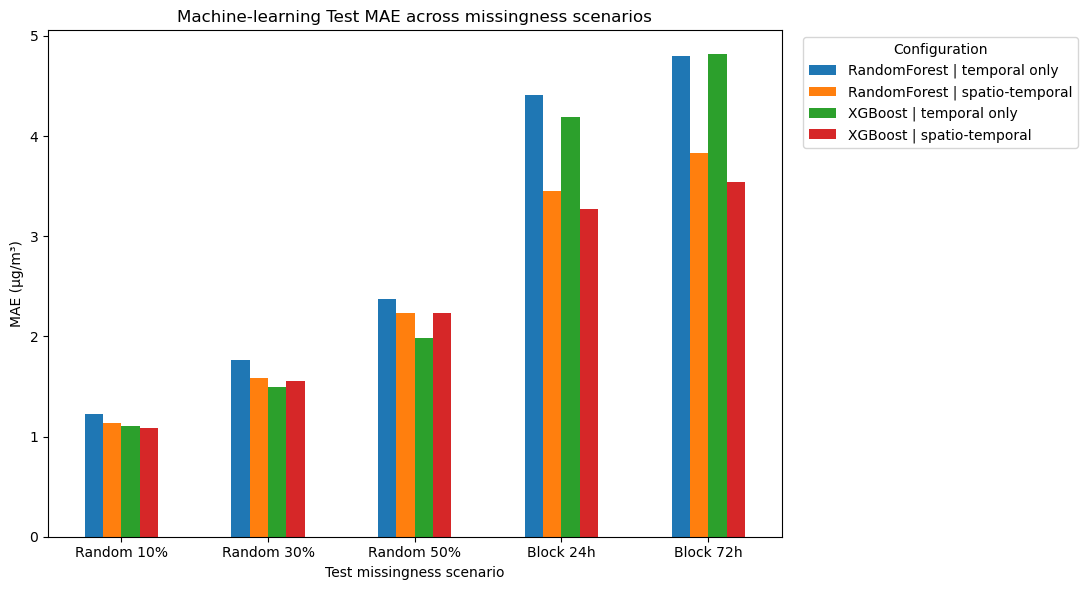

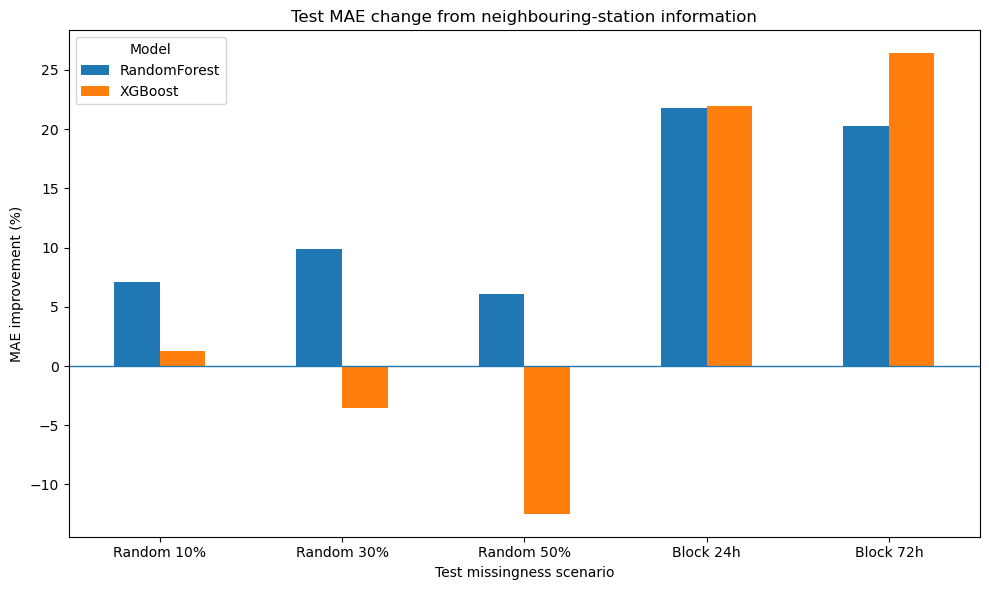

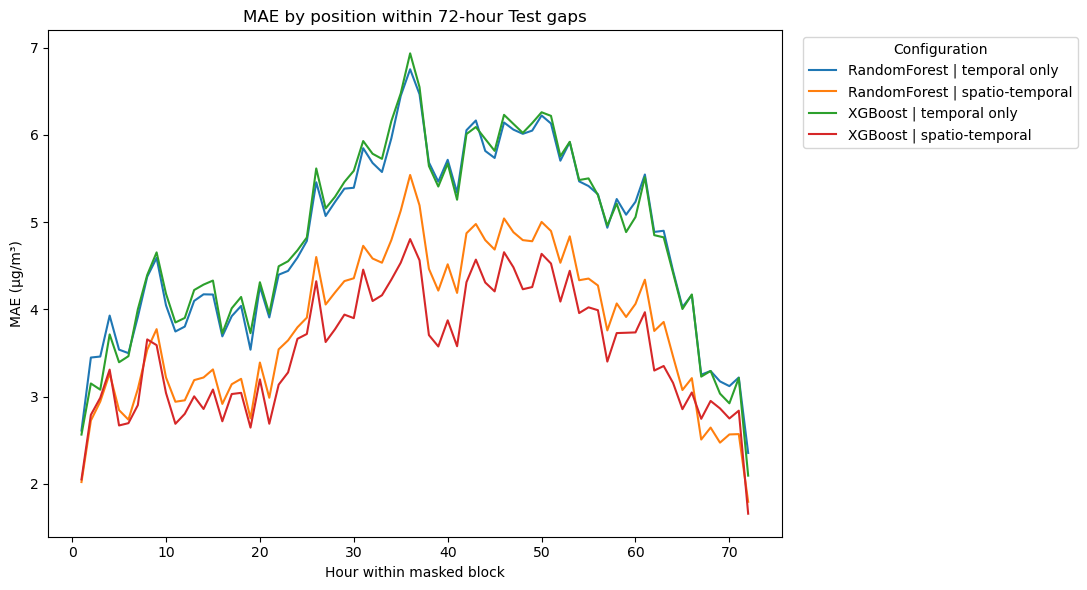

Three final ML figures saved.


In [16]:
configuration_order = [
    "RandomForest | temporal only",
    "RandomForest | spatio-temporal",
    "XGBoost | temporal only",
    "XGBoost | spatio-temporal",
]

scenario_labels = {
    "random10_point": "Random 10%",
    "random30_point": "Random 30%",
    "random50_point": "Random 50%",
    "block24_10percent": "Block 24h",
    "block72_10percent": "Block 72h",
}

figure_paths = {}


# Figure 1: final Test MAE by scenario and configuration.
mae_figure_df = overall_metrics_df.copy()

mae_figure_df[
    "Configuration"
] = (
    mae_figure_df[
        "Model"
    ]
    + " | "
    + mae_figure_df[
        "FeatureSet"
    ].map(
        {
            "temporal_only": (
                "temporal only"
            ),
            "spatio_temporal": (
                "spatio-temporal"
            ),
        }
    )
)

mae_pivot = (
    mae_figure_df
    .pivot(
        index="Scenario",
        columns="Configuration",
        values="MAE",
    )
    .reindex(
        SCENARIOS
    )[
        configuration_order
    ]
)

mae_pivot.index = [
    scenario_labels[
        scenario
    ]
    for scenario in mae_pivot.index
]

mae_ax = mae_pivot.plot(
    kind="bar",
    figsize=(11, 6),
)

mae_ax.set_title(
    "Machine-learning Test MAE across missingness scenarios"
)
mae_ax.set_xlabel(
    "Test missingness scenario"
)
mae_ax.set_ylabel(
    "MAE (µg/m³)"
)
mae_ax.tick_params(
    axis="x",
    rotation=0,
)
mae_ax.legend(
    title="Configuration",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)
mae_ax.figure.tight_layout()

mae_figure_path = (
    FIGURE_DIR
    / "ml_final_test_mae_by_scenario.png"
)

mae_ax.figure.savefig(
    mae_figure_path,
    dpi=300,
    bbox_inches="tight",
)
plt.show()
plt.close(
    mae_ax.figure
)

figure_paths[
    "FinalTestMAEByScenario"
] = str(
    mae_figure_path
)


# Figure 2: RQ3 spatial improvement by model and scenario.
rq3_figure_df = (
    rq3_overall_df
    .pivot(
        index="Scenario",
        columns="Model",
        values="MAEImprovementPercent",
    )
    .reindex(
        SCENARIOS
    )[
        MODEL_NAMES
    ]
)

rq3_figure_df.index = [
    scenario_labels[
        scenario
    ]
    for scenario in rq3_figure_df.index
]

rq3_ax = rq3_figure_df.plot(
    kind="bar",
    figsize=(10, 6),
)

rq3_ax.axhline(
    0,
    linewidth=1,
)
rq3_ax.set_title(
    "Test MAE change from neighbouring-station information"
)
rq3_ax.set_xlabel(
    "Test missingness scenario"
)
rq3_ax.set_ylabel(
    "MAE improvement (%)"
)
rq3_ax.tick_params(
    axis="x",
    rotation=0,
)
rq3_ax.legend(
    title="Model",
)
rq3_ax.figure.tight_layout()

rq3_figure_path = (
    FIGURE_DIR
    / "ml_rq3_spatial_mae_improvement.png"
)

rq3_ax.figure.savefig(
    rq3_figure_path,
    dpi=300,
    bbox_inches="tight",
)
plt.show()
plt.close(
    rq3_ax.figure
)

figure_paths[
    "RQ3SpatialMAEImprovement"
] = str(
    rq3_figure_path
)


# Figure 3: exact position within the 72-hour block gap.
block72_figure_df = (
    block_gap_hourly_profile_df.loc[
        block_gap_hourly_profile_df[
            "Scenario"
        ].eq(
            "block72_10percent"
        )
    ]
    .copy()
)

block72_figure_df[
    "Configuration"
] = (
    block72_figure_df[
        "Model"
    ]
    + " | "
    + block72_figure_df[
        "FeatureSet"
    ].map(
        {
            "temporal_only": (
                "temporal only"
            ),
            "spatio_temporal": (
                "spatio-temporal"
            ),
        }
    )
)

block72_pivot = (
    block72_figure_df
    .pivot(
        index="GapPositionHour",
        columns="Configuration",
        values="MAE",
    )[
        configuration_order
    ]
)

block72_ax = block72_pivot.plot(
    kind="line",
    figsize=(11, 6),
)

block72_ax.set_title(
    "MAE by position within 72-hour Test gaps"
)
block72_ax.set_xlabel(
    "Hour within masked block"
)
block72_ax.set_ylabel(
    "MAE (µg/m³)"
)
block72_ax.legend(
    title="Configuration",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)
block72_ax.figure.tight_layout()

block72_figure_path = (
    FIGURE_DIR
    / "ml_block72_gap_position_mae.png"
)

block72_ax.figure.savefig(
    block72_figure_path,
    dpi=300,
    bbox_inches="tight",
)
plt.show()
plt.close(
    block72_ax.figure
)

figure_paths[
    "Block72GapPositionMAE"
] = str(
    block72_figure_path
)

for figure_name, figure_path in (
    figure_paths.items()
):
    if not Path(
        figure_path
    ).exists():
        raise FileNotFoundError(
            f"Final figure was not saved: {figure_name}"
        )

print(
    "Three final ML figures saved."
)


## Step 11 : Final Output Audit

The final audit confirms that the complete 20-evaluation Test grid exists, all predictions have coverage, the shared full-tuning protocol is recorded, tuning/fit/inference costs are available, protocol-specific model artifacts exist, and all required tables and figures were saved.


In [17]:
environment_information = {
    "PythonVersion": sys.version.split()[0],
    "Platform": platform.platform(),
    "Processor": platform.processor(),
    "LogicalCPUCount": os.cpu_count(),
    "PandasVersion": pd.__version__,
    "NumPyVersion": np.__version__,
    "ScikitLearnVersion": sklearn.__version__,
    "XGBoostVersion": package_version(
        "xgboost"
    ),
    "RuntimeRequestedNJobs": (
        RUNTIME_N_JOBS
    ),
    "RuntimeEffectiveWorkers": 1,
    "FinalFitRepeats": (
        FINAL_FIT_REPEATS
    ),
    "InferenceRepeats": (
        INFERENCE_REPEATS
    ),
    "PipelineVersion": (
        ML_PIPELINE_VERSION
    ),
    "TuningProtocol": (
        TUNING_PROTOCOL
    ),
    "TuningProtocolVersion": (
        TUNING_PROTOCOL_VERSION
    ),
    "SelectionMetric": (
        TUNING_METRIC
    ),
    "SelectionSortColumns": (
        SELECTION_SORT_COLUMNS
    ),
    "TuningScenarios": (
        SCENARIOS
    ),
    "ScenarioFamilies": (
        SCENARIO_FAMILIES
    ),
    "FamilyWeights": (
        FAMILY_WEIGHTS
    ),
    "NestedRandomConditions": True,
    "TuningInputDataFingerprint": (
        CURRENT_TUNING_DATA_FINGERPRINT
    ),
    "ScenarioDataFingerprints": (
        CURRENT_SCENARIO_DATA_FINGERPRINTS
    ),
    "TuningManifestPath": str(
        TUNING_MANIFEST_PATH
    ),
    "TuningRuntimeSummaryPath": str(
        TUNING_RUNTIME_SUMMARY_PATH
    ),
    "RandomSeed": SEED,
    "PredictionClippingApplied": False,
}

environment_path = (
    FINAL_OUTPUT_DIR
    / "computational_environment_final_evaluation.json"
)

atomic_write_json(
    environment_information,
    environment_path,
)

expected_pairs = {
    (
        scenario,
        model_name,
        feature_set_name,
    )
    for scenario in SCENARIOS
    for model_name in MODEL_NAMES
    for feature_set_name in FEATURE_SETS
}

observed_pairs = set(
    overall_metrics_df[
        [
            "Scenario",
            "Model",
            "FeatureSet",
        ]
    ].itertuples(
        index=False,
        name=None,
    )
)

if observed_pairs != expected_pairs:
    raise RuntimeError(
        "The final 20-evaluation grid is incomplete."
    )

if not overall_metrics_df[
    "PredictionCoverage"
].eq(1.0).all():
    raise RuntimeError(
        "Some final Test predictions are missing."
    )

if not overall_metrics_df[
    "NMissingPredictions"
].eq(0).all():
    raise RuntimeError(
        "Some final Test predictions are missing."
    )

required_output_paths = [
    FINAL_OUTPUT_DIR
    / "scenario_input_audit.csv",
    FINAL_OUTPUT_DIR
    / "mask_audit_by_split_station.csv",
    tuning_selection_audit_path,
    FINAL_OUTPUT_DIR
    / "ml_final_test_predictions.csv",
    FINAL_OUTPUT_DIR
    / "ml_final_test_metrics.csv",
    FINAL_OUTPUT_DIR
    / "ml_final_test_metrics_by_station.csv",
    FINAL_OUTPUT_DIR
    / "ml_prediction_diagnostics.csv",
    FINAL_OUTPUT_DIR
    / "ml_rq3_spatial_ablation.csv",
    FINAL_OUTPUT_DIR
    / "ml_rq3_spatial_ablation_by_station.csv",
    FINAL_OUTPUT_DIR
    / "ml_block_gap_predictions_with_position.csv",
    FINAL_OUTPUT_DIR
    / "ml_block_gap_hourly_error_profile.csv",
    FINAL_OUTPUT_DIR
    / "ml_block_gap_region_metrics.csv",
    FINAL_OUTPUT_DIR
    / "ml_block_gap_edge_middle_comparison.csv",
    FINAL_OUTPUT_DIR
    / "ml_accuracy_cost_summary.csv",
    FINAL_OUTPUT_DIR
    / "ml_final_runtime_records.csv",
    FINAL_OUTPUT_DIR
    / "ml_final_runtime_summary.csv",
    environment_path,
    *[
        Path(
            figure_path
        )
        for figure_path in (
            figure_paths.values()
        )
    ],
]

if not feature_importance_df.empty:
    required_output_paths.append(
        FINAL_OUTPUT_DIR
        / "ml_feature_importance.csv"
    )

for path in required_output_paths:
    if not path.exists():
        raise FileNotFoundError(
            f"Required final output is missing: {path}"
        )

model_artifact_paths = []
model_manifest_paths = []

for model_name in MODEL_NAMES:
    for feature_set_name in FEATURE_SETS:
        model_path, manifest_path = (
            final_model_paths(
                model_name,
                feature_set_name,
            )
        )

        if not model_path.exists():
            raise FileNotFoundError(
                f"Final model missing: {model_path}"
            )

        if not manifest_path.exists():
            raise FileNotFoundError(
                f"Final model manifest missing: {manifest_path}"
            )

        model_manifest = read_json(
            manifest_path
        )

        if model_manifest.get(
            "TuningProtocolVersion"
        ) != TUNING_PROTOCOL_VERSION:
            raise RuntimeError(
                "A final-model manifest uses the wrong "
                f"tuning protocol: {manifest_path}"
            )

        if model_manifest.get(
            "SelectionMetric"
        ) != TUNING_METRIC:
            raise RuntimeError(
                "A final-model manifest uses the wrong "
                f"selection metric: {manifest_path}"
            )

        model_artifact_paths.append(
            str(model_path)
        )

        model_manifest_paths.append(
            str(manifest_path)
        )

final_manifest_path = (
    FINAL_OUTPUT_DIR
    / "ml_final_evaluation_manifest.json"
)

atomic_write_json(
    {
        "Status": "complete",
        "ExpectedEvaluations": (
            expected_evaluations
        ),
        "ObservedEvaluations": len(
            overall_metrics_df
        ),
        "Models": MODEL_NAMES,
        "FeatureSets": FEATURE_SETS,
        "Scenarios": SCENARIOS,
        "EvaluationSplit": TEST_LABEL,
        "FinalFitRepeats": (
            FINAL_FIT_REPEATS
        ),
        "InferenceRepeats": (
            INFERENCE_REPEATS
        ),
        "RuntimeNJobs": (
            RUNTIME_N_JOBS
        ),
        "PredictionClippingApplied": False,
        "TuningProtocol": (
            TUNING_PROTOCOL
        ),
        "TuningProtocolVersion": (
            TUNING_PROTOCOL_VERSION
        ),
        "SelectionMetric": (
            TUNING_METRIC
        ),
        "SelectionSortColumns": (
            SELECTION_SORT_COLUMNS
        ),
        "TuningScenarios": (
            SCENARIOS
        ),
        "ScenarioFamilies": (
            SCENARIO_FAMILIES
        ),
        "FamilyWeights": (
            FAMILY_WEIGHTS
        ),
        "NestedRandomConditions": True,
        "PipelineVersion": (
            ML_PIPELINE_VERSION
        ),
        "InputDataFingerprint": (
            CURRENT_TUNING_DATA_FINGERPRINT
        ),
        "ScenarioDataFingerprints": (
            CURRENT_SCENARIO_DATA_FINGERPRINTS
        ),
        "TuningManifestPath": str(
            TUNING_MANIFEST_PATH
        ),
        "TuningRuntimeSummaryPath": str(
            TUNING_RUNTIME_SUMMARY_PATH
        ),
        "TuningArtifacts": {
            model_name: {
                feature_set_name: str(
                    TUNING_ARTIFACT_PATHS[
                        model_name
                    ][feature_set_name]
                )
                for feature_set_name in (
                    FEATURE_SETS
                )
            }
            for model_name in MODEL_NAMES
        },
        "ModelArtifacts": (
            model_artifact_paths
        ),
        "ModelManifests": (
            model_manifest_paths
        ),
        "OutputFiles": [
            str(path)
            for path in required_output_paths
        ],
        "Figures": (
            figure_paths
        ),
        "EnvironmentPath": str(
            environment_path
        ),
    },
    final_manifest_path,
)

print(
    "Final shared-tuning ML evaluation audit passed."
)
print(
    f"Manifest saved to: {final_manifest_path}"
)
print(
    "Machine-learning final evaluation is complete."
)


Final shared-tuning ML evaluation audit passed.
Manifest saved to: C:\Users\Msi\Desktop\DISSERTATION\Codes\results\machine_learning\final_evaluation\shared_family_balanced_v1\ml_final_evaluation_manifest.json
Machine-learning final evaluation is complete.
